# 2026 Election — Markets vs. Forecasts
## Congress Scorecard
This scorecard asks six questions about the November 2 forecasts: who picked the winners, how many non-Republican wins each source expected, which results were most surprising, where the forecasts disagreed, how they assessed House control, and how Cook's ratings performed.

The **Non-Republican Candidate** is the recorded Democrat or independent; the opposing candidate is Republican in all 35 races. Non-Republican wins, Democratic-caucus seats, and chamber-control probabilities are distinct quantities. The [analysis plan](../docs/analysis-plan.md) defines the comparisons; the [data guide](../docs/data-and-scoring.md) documents evidence and eligibility.

In [1]:
import json
from html import escape
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, HTML, Image
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from congress_scorecard import load_context, select_sample, calls_correct, expected_wins, match_sample, paired_difference, probability_score, senate_caucus_seats, house_control, house_seat_error, house_expected_seats, project_root
from congress_scorecard.plotting import make_canvas, save_chart, source_colors, graphics_assets, party_colors
from congress_scorecard.chart_lint import lint_chart
from congress_scorecard.data import sha256
ctx = load_context('01_congress_scorecard')
data = ctx.inputs
senate = data.senate
assert senate.Candidate_A_Party.isin(['Democratic', 'Independent']).all()
assert senate.Candidate_B_Party.eq('Republican').all()
SOURCES = {
    'Kalshi': ('p_kalshi', 'kalshi'),
    'Economist': ('p_economist', 'economist'),
    'VoteHub Complete': ('p_votehub', 'votehub'),
    'Cook': ('p_cook_primary', 'cook'),
}
display_names = {
    'Kalshi': 'Kalshi',
    'Economist': 'The Economist',
    'VoteHub Complete': 'VoteHub',
    'Cook': 'Cook',
}
colors = source_colors()
BLUE, GOLD = ('#80C2FC', '#EEEAAC')
synthetic, snapshot_label = (data.manifest['synthetic'], data.snapshot_id)
scratch = project_root().parent / '_scratch' / 'part-2' / ctx.output_dir.name
scratch.mkdir(parents=True, exist_ok=True)
figure_records, score_records = ([], {})
layout_checks = {}
metadata = {
    'snapshot': snapshot_label,
    'synthetic': synthetic,
    'senate_timestamp': data.manifest['senate_timestamp'],
    'house_timestamp': data.manifest['house_timestamp'],
}

def say(text):
    display(Markdown(text))

def present(title, frame):
    headers = ''.join((f'<th style="padding:10px 14px;text-align:left;border-bottom:2px solid #80C2FC">{escape(str(c))}</th>' for c in frame))
    rows = []
    for row in frame.itertuples(index=False, name=None):
        cells = []
        for value in row:
            numeric = isinstance(value, (float, int, np.number)) and (not isinstance(value, (bool, np.bool_)))
            text = '—' if pd.isna(value) else f'{value:,.2f}' if numeric and (not float(value).is_integer()) else str(int(value)) if numeric else str(value)
            cells.append(f"""<td style="padding:9px 14px;text-align:{('right' if numeric else 'left')};border-bottom:1px solid #bbb">{escape(text)}</td>""")
        rows.append('<tr>' + ''.join(cells) + '</tr>')
    display(HTML(f"""<p><strong>{escape(title)}</strong></p><table style="border-collapse:collapse;font:inherit"><thead><tr>{headers}</tr></thead><tbody>{''.join(rows)}</tbody></table>"""))

def save_table(frame, name, show=False):
    exported = frame.assign(**metadata)
    exported.to_csv(ctx.tables_dir / f'{name}.csv', index=False)
    if show:
        present(name.replace('_', ' ').capitalize(), frame)
    return exported

def record(name, result):
    score_records[name] = result.summary()
    return result

def capture(chamber):
    return pd.Timestamp(data.manifest[chamber.lower() + '_timestamp']).tz_convert('America/New_York').strftime('%b %d, %Y, %I:%M %p %Z').replace(' 0', ' ')

def footer(detail, chamber='Senate', kalshi=True):
    status = 'SYNTHETIC TEST OUTCOMES — NOT ELECTION FINDINGS' if synthetic else 'Preliminary; Kalshi probabilities provisional' if kalshi else 'Preliminary'
    source = 'software fixture' if synthetic else 'DDHQ'
    return f'Forecasts: Nov 2, 2026. Results: {source}, {capture(chamber)}. {status}. {detail}'

def text(cv, x, y, value, px=32, color='white', ha='left', role='body', va='center'):
    left, bottom, right, top = cv.plot_rect
    return cv.fig.text(
        (left + x * (right - left)) / cv.W,
        (bottom + y * (top - bottom)) / cv.H,
        str(value),
        ha=ha,
        va=va,
        color=color,
        fontproperties=cv.fp(role),
        fontsize=px * 0.72,
    )

def rule(cv, y, left=0, right=1, color='#2A3A86', width=1):
    x0, y0, x1, y1 = cv.plot_rect
    cv.fig.add_artist(Line2D(
        [(x0 + left * (x1 - x0)) / cv.W, (x0 + right * (x1 - x0)) / cv.W],
        [(y0 + y * (y1 - y0)) / cv.H] * 2,
        transform=cv.fig.transFigure,
        color=color,
        linewidth=width,
    ))

def export_chart(cv, name, frame):
    paths = save_chart(cv, name, out_dir=ctx.figures_dir, scratch_dir=scratch)
    lint = lint_chart(cv, paths['png'])
    (scratch / f'{name}.lint.json').write_text(json.dumps(lint, indent=2), encoding='utf-8')
    assert lint['passed'], lint['failures']
    axes_details = []
    for ax in cv.fig.axes:
        if ax.get_xlabel():
            axes_details.append({
                'xlabel': ax.get_xlabel(),
                'labelpad_points': ax.xaxis.labelpad,
                'expected_labelpad_points': 4 + 8 * cv.scale * 0.72,
            })
    layout_checks.setdefault(name, {})['x_axes'] = axes_details
    (scratch / f'{name}.layout.json').write_text(
        json.dumps(layout_checks[name], indent=2),
        encoding='utf-8',
    )
    save_table(frame, f'plot_{name}')
    figure_records.append({'image': f'{name}.png', 'data': f'plot_{name}.csv', 'lint_passed': True})
    display(Image(data=paths['png'].read_bytes(), width=960))
    cv.fig.clear()
say('**SYNTHETIC SOFTWARE FIXTURE — invented outcomes, not election findings.**' if synthetic else '**Preliminary results.** Only verified DDHQ calls are used for outcome comparisons.')
say(f"**Forecasts:** November 2, 2026. **Senate capture:** {capture('Senate')}. **House capture:** {capture('House')}. **Snapshot:** `{snapshot_label}`.")
say(f"**Coverage:** {int(senate.call_eligible.sum())} of {len(senate)} Senate races eligible; {int(select_sample(senate, 'non_solid').call_eligible.sum())} of {len(select_sample(senate, 'non_solid'))} races eligible among Cook's Likely, Lean and Toss-Up ratings. " + ('Excluded races: ' + ', '.join(senate.index[~senate.call_eligible]) + '.' if (~senate.call_eligible).any() else 'No Senate races are excluded.'))
save_table(pd.DataFrame([metadata]), 'snapshot')
save_table(
    senate.loc[
        ~senate.call_eligible,
        ['result_call_status', 'result_recount_status', 'call_exclusion'],
    ].reset_index(),
    'excluded_senate',
)

**Preliminary results.** Only verified DDHQ calls are used for outcome comparisons.

**Forecasts:** November 2, 2026. **Senate capture:** Nov 4, 2026, 10:05 PM EST. **House capture:** Nov 4, 2026, 10:20 PM EST. **Snapshot:** `ddhq-20261104-222052-est`.

**Coverage:** 33 of 35 Senate races eligible; 13 of 15 races eligible among Cook's Likely, Lean and Toss-Up ratings. Excluded races: AK-SEN, MS-SEN.

,race_id,result_call_status,result_recount_status,call_exclusion,snapshot,synthetic,senate_timestamp,house_timestamp
0,AK-SEN,pending,NaN,no verified DDHQ call,ddhq-20261104-222052-est,False,2026-11-04T22:05:02.090703-05:00,2026-11-04T22:20:52.470153-05:00
1,MS-SEN,pending,NaN,no verified DDHQ call,ddhq-20261104-222052-est,False,2026-11-04T22:05:02.090703-05:00,2026-11-04T22:20:52.470153-05:00


## 1. Calls Correct
A forecast makes a directional call only when it gives one side more than 50%. At exactly 50%, it has **no favorite**; DDHQ resolution is tracked separately. Each ratio below is **correct calls / calls made among eligible resolved races**.

The highlighted group contains races Cook rated **Likely, Lean or Toss-Up**, excluding its safest **Solid** ratings. The shared-favorites group contains races where Cook favored one side; all four sources favored that same candidate.

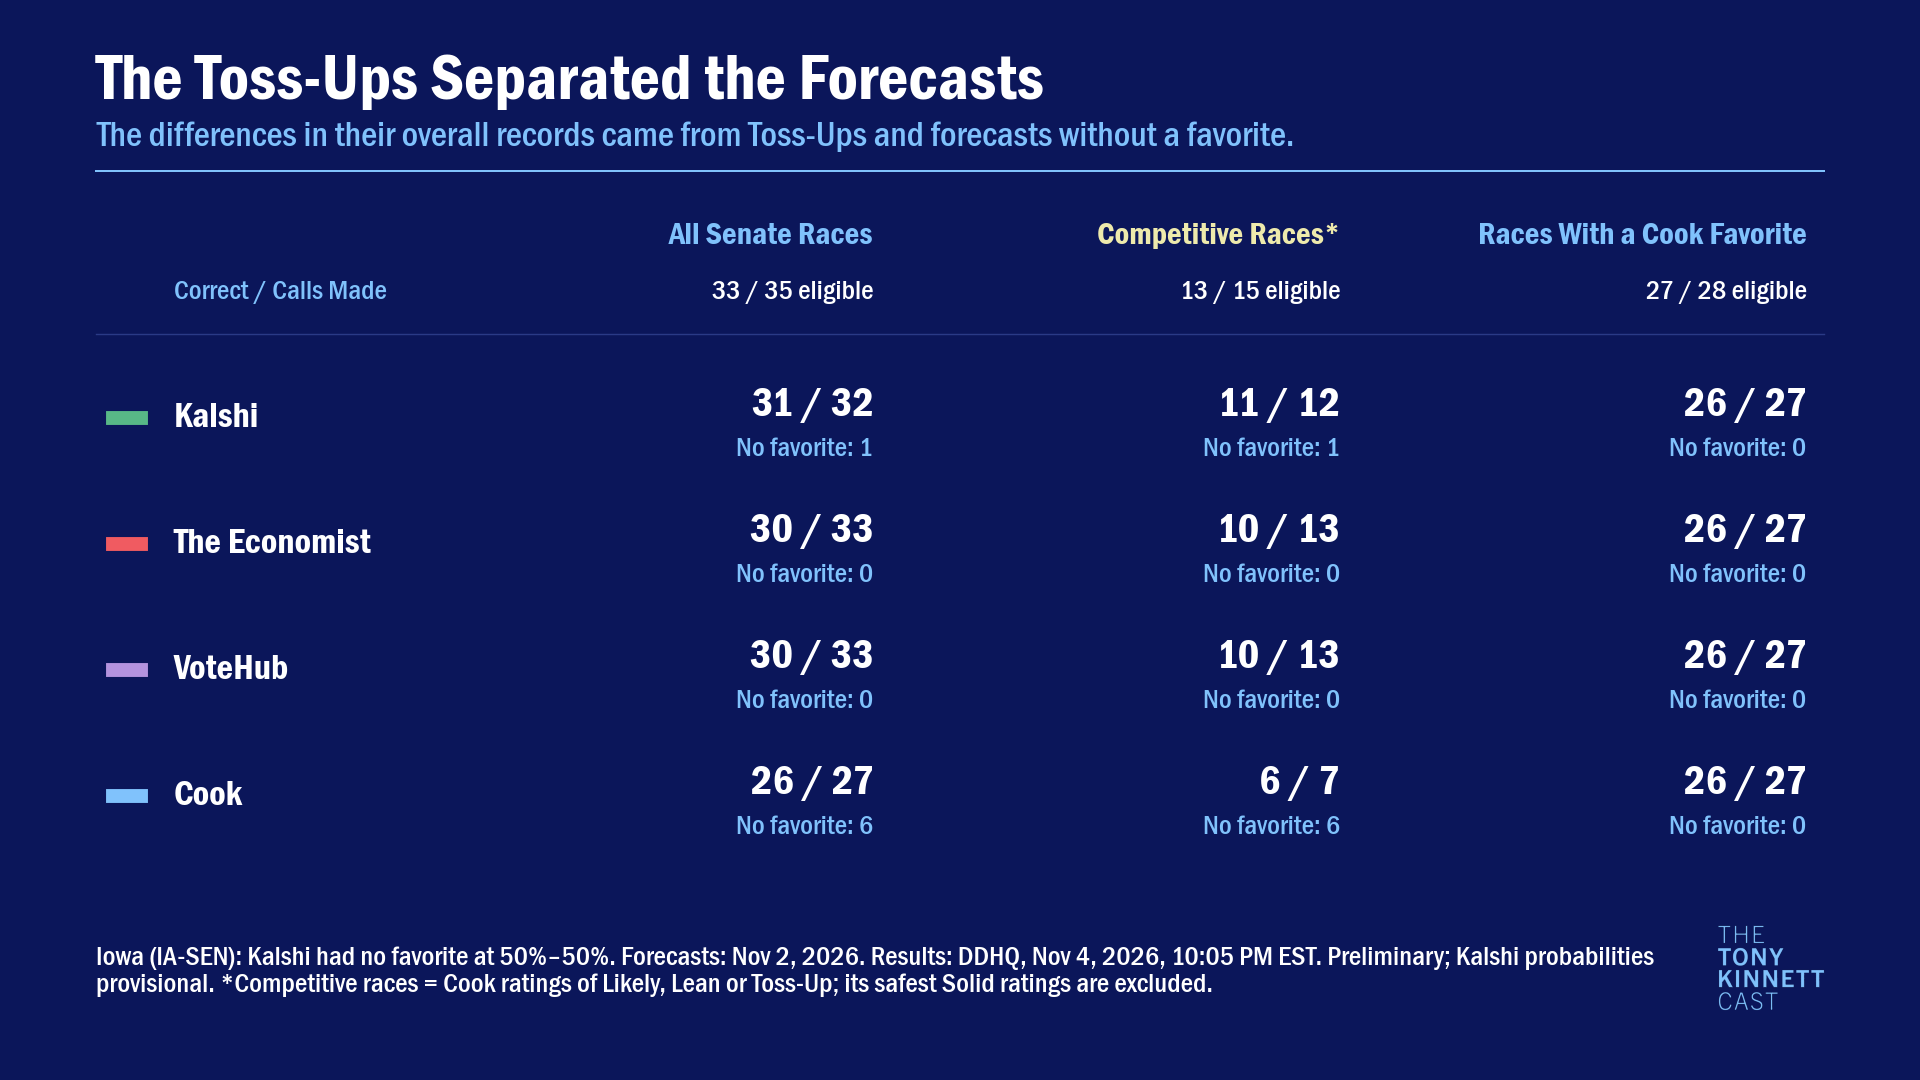

**Kalshi's even forecast:** IA-SEN recorded 50% for each candidate. It has no directional favorite, but remains eligible for probability scoring when its outcome meets the evidence rules.

All four sources picked the same side on the shared directional set: **26 of 27 correct** among 27 eligible races out of 28 planned. The differences in the broader samples come from Toss-Ups and abstentions. These counts do not measure probability calibration.

In [2]:
call_rows = []
for sample, title in [('all', 'All races'), ('non_solid', 'Cook non-Solid'), ('cook_directional', 'Common Cook-directional')]:
    for source, (column, _) in SOURCES.items():
        result = record(f'calls/{sample}/{source}', calls_correct(select_sample(senate, sample), column))
        value = result.value or {'correct': 0, 'calls_made': 0, 'abstentions': 0, 'accuracy': None}
        call_rows.append({
            'sample': title,
            'source': source,
            'planned': result.n_planned,
            'eligible': result.n_eligible,
            'excluded': result.n_planned - result.n_eligible,
            **value,
        })
call_table = pd.DataFrame(call_rows)
save_table(call_table, 'calls')
cv = make_canvas(
    'The Toss-Ups Separated the Forecasts',
    subtitle='The differences in their overall records came from Toss-Ups and forecasts without a favorite.',
    source='Iowa (IA-SEN): Kalshi had no favorite at 50%–50%. ' + footer('*Competitive races = Cook ratings of Likely, Lean or Toss-Up; its safest Solid ratings are excluded.'),
)
positions = [0.45, 0.72, 0.99]
for x, sample, heading in zip(positions, ['All races', 'Cook non-Solid', 'Common Cook-directional'], ['All Senate Races', 'Competitive Races*', 'Races With a Cook Favorite']):
    rows = call_table[call_table['sample'].eq(sample)]
    text(
        cv,
        x,
        0.94,
        heading,
        px=32,
        ha='right',
        role='emphasis',
        color=GOLD if sample == 'Cook non-Solid' else BLUE,
    )
    text(
        cv,
        x,
        0.86,
        f'{int(rows.eligible.iloc[0])} / {int(rows.planned.iloc[0])} eligible',
        px=28,
        ha='right',
    )
text(cv, 0.045, 0.86, 'Correct / Calls Made', px=28, color=BLUE)
rule(cv, 0.8)
for y, source in zip([0.68, 0.5, 0.32, 0.14], SOURCES):
    text(cv, 0.045, y, display_names[source], px=36, role='emphasis')
    rule(cv, y, 0.01, 0.026, color=colors[SOURCES[source][1]], width=10)
    for x, sample in zip(positions, ['All races', 'Cook non-Solid', 'Common Cook-directional']):
        row = call_table[call_table.source.eq(source) & call_table['sample'].eq(sample)].iloc[0]
        value = f'{int(row.correct)} / {int(row.calls_made)}' if row.calls_made else '—'
        text(cv, x, y + 0.018, value, px=42, ha='right', role='emphasis')
        text(
            cv,
            x,
            y - 0.045,
            f'No favorite: {int(row.abstentions)}' if row.eligible else 'No eligible calls',
            px=28,
            ha='right',
            color=BLUE,
        )
export_chart(cv, '01-correct-calls', call_table)
even_races = senate.index[senate.p_kalshi.eq(0.5)].tolist()
if even_races:
    say("**Kalshi's even forecast:** " + ', '.join(even_races) + ' recorded 50% for each candidate. It has no directional favorite, but remains eligible for probability scoring when its outcome meets the evidence rules.')
common = call_table[call_table['sample'].eq('Common Cook-directional')]
if common.eligible.gt(0).all():
    first = common.iloc[0]
    say(f'All four sources picked the same side on the shared directional set: **{int(first.correct)} of {int(first.calls_made)} correct** among {int(first.eligible)} eligible races out of {int(first.planned)} planned. The differences in the broader samples come from Toss-Ups and abstentions. These counts do not measure probability calibration.')
else:
    say('No eligible common-set outcomes are available. The forecast-defined sample is retained.')

## 2. Expected Versus Actual Non-Republican Wins
Full-field expectations are forecasts across all 35 races. The outcome comparison uses only the **same resolved, eligible races on both sides**. Each bar adds that source's non-Republican win probabilities; the yellow line marks the number of actual wins.

The standard deviation, √Σp(1−p), assumes independent races. It omits cross-race covariance and can understate spread when national conditions move races together. It is not a confidence interval.

Source,Expected Non-Republican Wins,Independent SD
Kalshi,18.96,1.70
The Economist,16.93,1.61
VoteHub,18.10,1.62
Cook,16.52,1.51


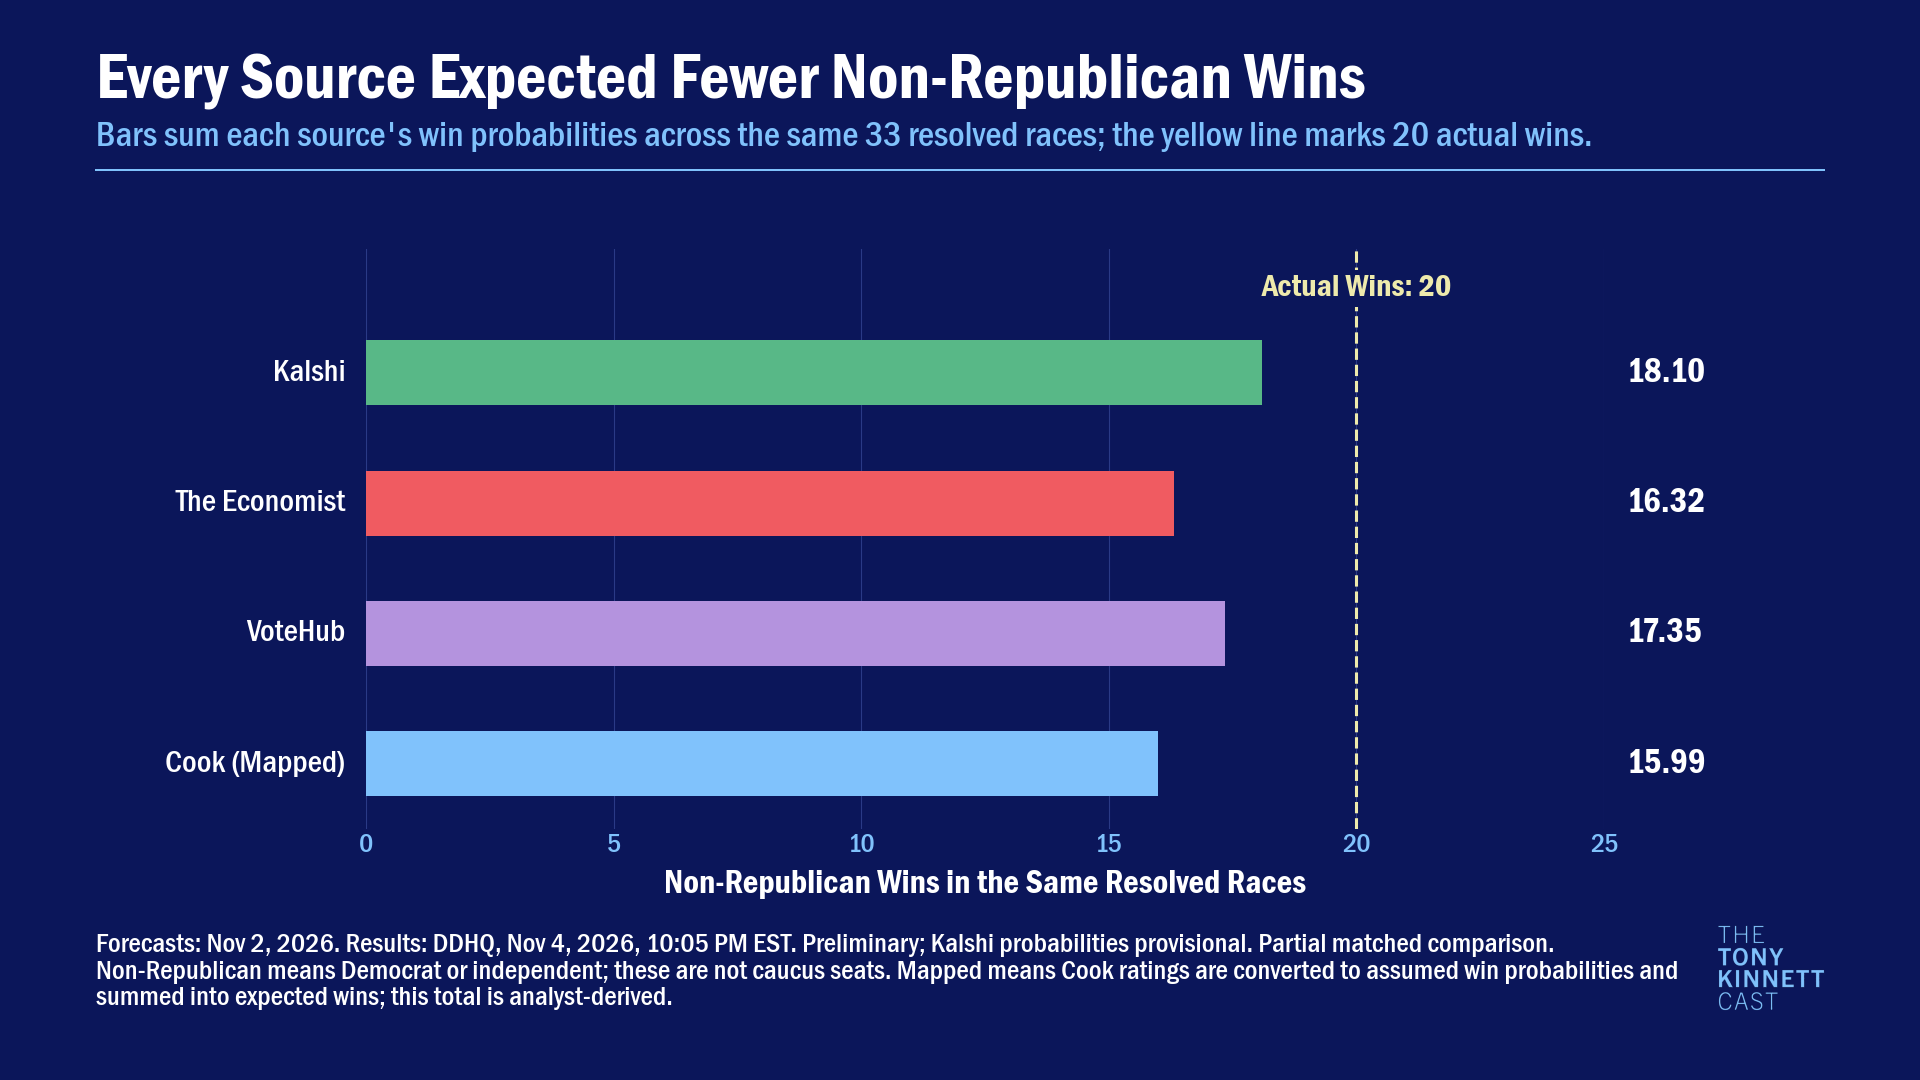

Across 33 eligible races, non-Republican candidates won **20**. Kalshi expected 18.10; The Economist expected 16.32; VoteHub expected 17.35; Cook expected 15.99. These are partial results, not final seat totals.

Source,Signed error,Absolute error,Independent SD
Kalshi,-1.90,1.90,1.60
The Economist,-3.68,3.68,1.51
VoteHub,-2.65,2.65,1.52
Cook,-4.01,4.01,1.42


**Democratic-caucus seats and Senate control remain unavailable.** They require approved independent-caucus coding and supporting evidence, holdover seats, and a control tie convention. Expected non-Republican wins cannot supply these quantities.

In [3]:
expectation_rows = []
for source, (column, _) in SOURCES.items():
    result = record(f'expected/{source}', expected_wins(senate, column))
    full, matched = (senate[column], result.per_race[column])
    expectation_rows.append({
        'source': source,
        **result.value,
        'eligible': result.n_eligible,
        'excluded': result.n_planned - result.n_eligible,
        'full_field_independent_sd': float(np.sqrt((full * (1 - full)).sum())) if full.notna().all() else None,
        'eligible_independent_sd': float(np.sqrt((matched * (1 - matched)).sum())) if len(matched) else None,
    })
expectations = pd.DataFrame(expectation_rows)
save_table(
    expectations[['source', 'full_field_n', 'full_field_expected', 'full_field_independent_sd']],
    'full_field_forecasts',
)
save_table(
    expectations.drop(columns=['full_field_n', 'full_field_expected', 'full_field_independent_sd']),
    'matched_expected_wins',
)
view = expectations[['source', 'full_field_expected', 'full_field_independent_sd']].copy()
view.source = view.source.map(display_names)
present(
    'Full-field forecasts · all 35 races',
    view.rename(columns={
        'source': 'Source',
        'full_field_expected': 'Expected Non-Republican Wins',
        'full_field_independent_sd': 'Independent SD',
    }),
)
common_counts = len({tuple(score_records[f'expected/{source}']['race_ids']) for source in SOURCES}) == 1
if common_counts and expectations.eligible.gt(0).all():
    actual, n = (int(expectations.eligible_actual.iloc[0]), int(expectations.eligible.iloc[0]))
    headline = 'Every Source Expected Fewer Non-Republican Wins' if expectations.eligible_expected.lt(actual).all() else 'Expected and Actual Non-Republican Wins'
    cv = make_canvas(
        headline,
        subtitle=f"Bars sum each source's win probabilities across the same {n} resolved races; the yellow line marks {actual} actual wins." if expectations.eligible_expected.lt(actual).all() else f'Bars show expected wins in the same {n} resolved races; the yellow line marks {actual} actual wins.',
        source=footer(f"{('Partial' if n < len(senate) else 'Complete')} matched comparison. Non-Republican means Democrat or independent; these are not caucus seats. Mapped means Cook ratings are converted to assumed win probabilities and summed into expected wins; this total is analyst-derived."),
    )
    limit = 5 * int(np.ceil(max(actual, expectations.eligible_expected.max()) / 5) + 1)
    ax = cv.axes(left_pad=270, right_pad=220, bottom_pad=65, top_pad=55)
    bars = ax.barh(np.arange(len(expectations)), expectations.eligible_expected, height=0.5, color=[colors[SOURCES[source][1]] for source in expectations.source])
    np.testing.assert_allclose([bar.get_width() for bar in bars], expectations.eligible_expected)
    for i, row in enumerate(expectations.itertuples()):
        ax.annotate(
            'Cook (Mapped)' if row.source == 'Cook' else display_names[row.source],
            (0, i),
            xytext=(-15, 0),
            textcoords='offset points',
            ha='right',
            va='center',
            color='white',
            fontproperties=cv.fp('body'),
            fontsize=23,
        )
        ax.annotate(
            f'{row.eligible_expected:.2f}',
            (limit, i),
            xytext=(16, 0),
            textcoords='offset points',
            ha='left',
            va='center',
            color='white',
            fontproperties=cv.fp('emphasis'),
            fontsize=25,
        )
    ax.axvline(actual, color=GOLD, linewidth=2.2, linestyle='--')
    ax.annotate(
        f'Actual Wins: {actual}',
        (actual, -0.65),
        ha='center',
        va='center',
        color=GOLD,
        fontproperties=cv.fp('emphasis'),
        fontsize=23,
        bbox={'facecolor': '#0B165A', 'edgecolor': 'none', 'pad': 4},
    )
    ax.set(
        xlim=(0, limit),
        ylim=(3.5, -0.95),
        yticks=[],
        xticks=np.arange(0, limit + 1, 5),
        xlabel='Non-Republican Wins in the Same Resolved Races',
    )
    ax.xaxis.labelpad += 8 * cv.scale * 0.72
    ax.xaxis.grid(True, color='#2A3A86')
    ax.set_axisbelow(True)
    export_chart(
        cv,
        '02-expected-wins',
        expectations[['source', 'eligible_expected', 'eligible_actual', 'eligible']],
    )
    say(f'Across {n} eligible races, non-Republican candidates won **{actual}**. ' + '; '.join((f'{display_names[r.source]} expected {r.eligible_expected:.2f}' for r in expectations.itertuples())) + ('. These are partial results, not final seat totals.' if n < len(senate) else '. This is the complete selected field.'))
    view = expectations[['source', 'signed_error', 'absolute_error', 'eligible_independent_sd']].copy()
    view.source = view.source.map(display_names)
    present(
        f'Matched forecast error · {n} eligible races · forecast minus actual',
        view.rename(columns={
            'source': 'Source',
            'signed_error': 'Signed error',
            'absolute_error': 'Absolute error',
            'eligible_independent_sd': 'Independent SD',
        }),
    )
else:
    say('The matched outcome comparison is unavailable without eligible races shared by the sources.')
caucus_rows = []
for source, (column, _) in SOURCES.items():
    result = record(f'caucus/{source}', senate_caucus_seats(data, column))
    caucus_rows.append({'source': source, 'status': result.status, 'value': result.value})
save_table(pd.DataFrame(caucus_rows), 'caucus_gate')
say('**Democratic-caucus seats and Senate control remain unavailable.** They require approved independent-caucus coding and supporting evidence, holdover seats, and a control tie convention. Expected non-Republican wins cannot supply these quantities.')

## 3. Biggest Misses
Which eventual winners received the lowest probabilities? This comparison covers **Kalshi, The Economist and VoteHub**. It includes each source's five lowest-probability eligible winners, including ties at fifth place, and shows the recorded chance of the named winner—not vote share.

Cook is excluded from this graphic. The raw A/B winner-probability display remains distinct from proper scoring of the non-Republican win event when raw prices do not sum to one.

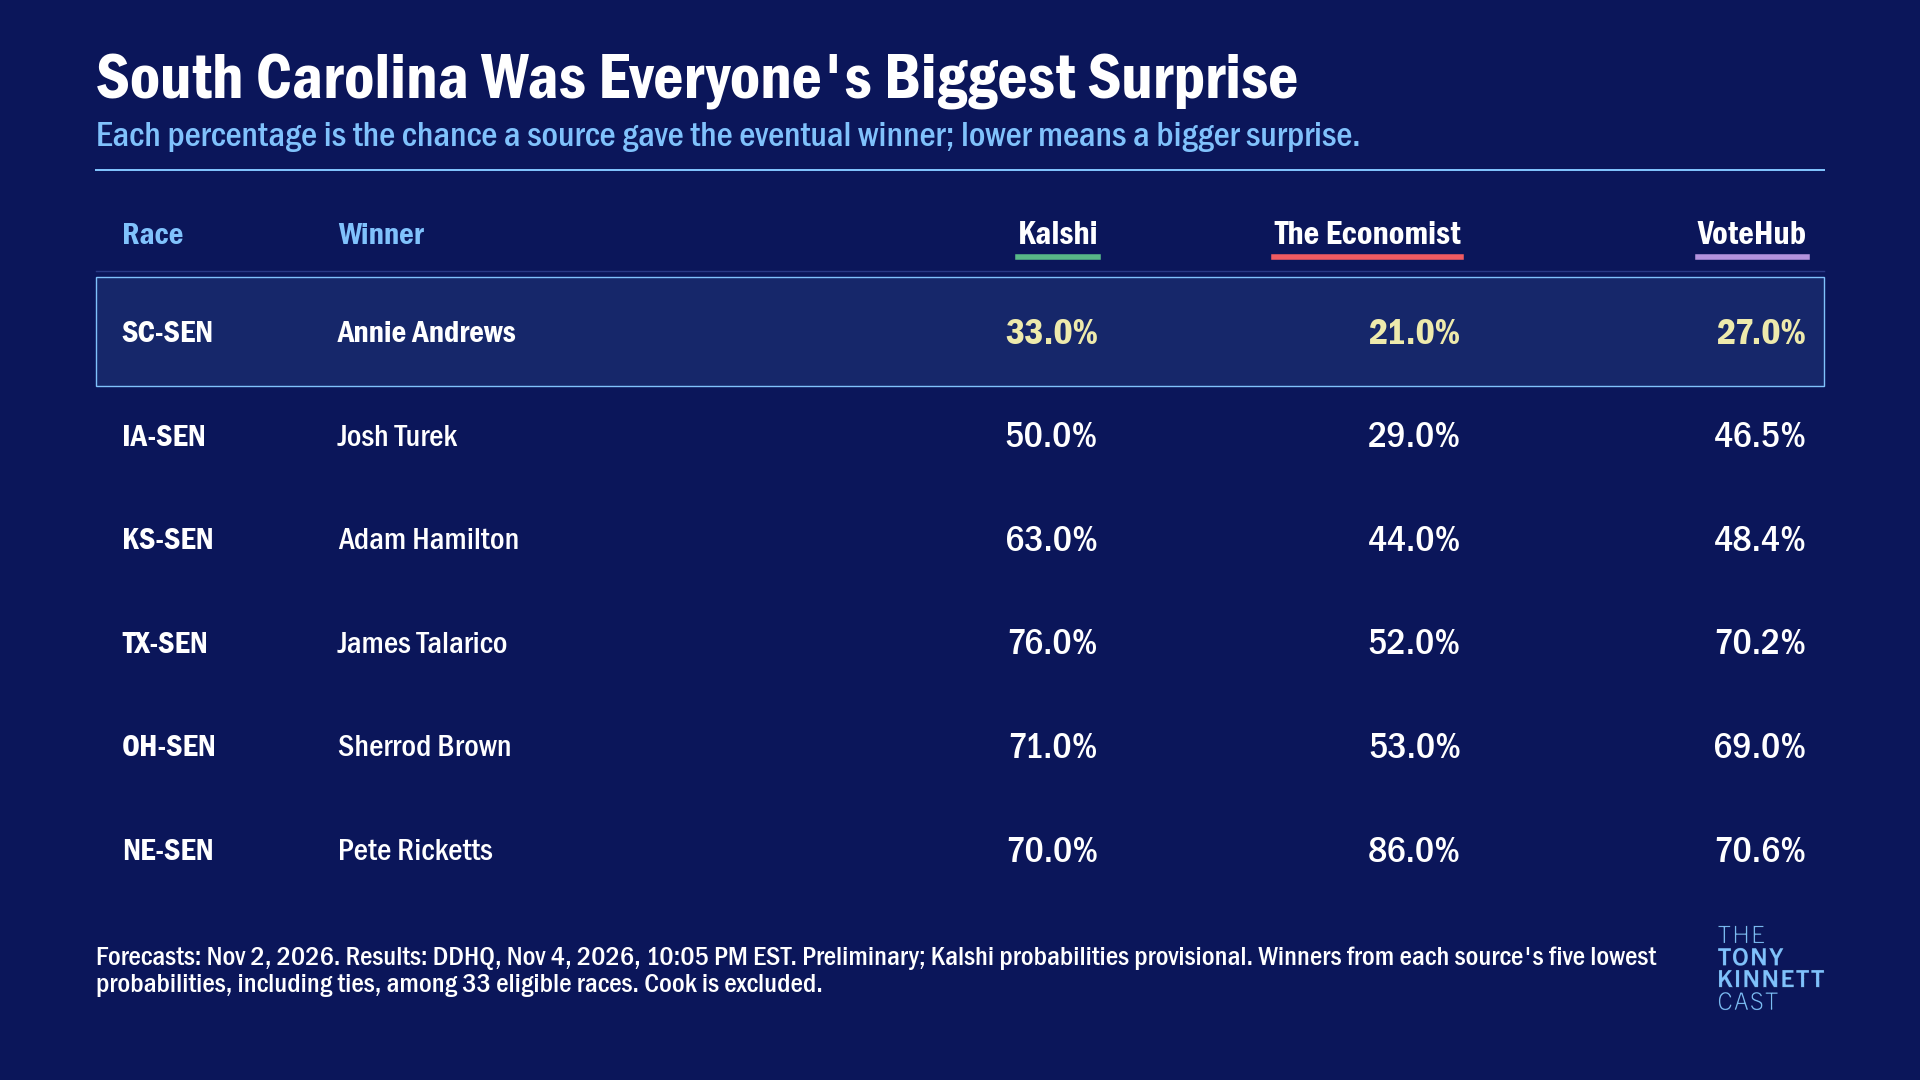

Kalshi's lowest-probability eligible winner was **Annie Andrews (SC-SEN)**, at **33.0%**. The comparison retains each source's lowest-probability winners and all cutoff ties.

In [4]:
def winner_probabilities(frame):
    rows = match_sample(frame, [column for column, _ in SOURCES.values()]).rows
    result = pd.DataFrame(index=rows.index)
    result['winner'] = rows.result_winner
    for source, (column, _) in SOURCES.items():
        label = {'Kalshi': 'Kalshi', 'Economist': 'Economist', 'VoteHub Complete': 'VoteHub'}.get(source)
        result[source] = rows[f'{label}_A_Probability'].where(
            rows.y.eq(1),
            rows[f'{label}_B_Probability'],
        ) if label else rows[column].where(rows.y.eq(1), 1 - rows[column])
    return result

def lowest_with_ties(frame, column, count=5):
    ordered = frame.reset_index().sort_values([column, 'race_id'], kind='stable')
    if len(ordered) > count:
        ordered = ordered[ordered[column].le(ordered.iloc[count - 1][column] + 1e-12)]
    return ordered.reset_index(drop=True)
winner_probs = winner_probabilities(senate)
save_table(winner_probs.reset_index(), 'winner_probabilities')
ranked = {}
for source in SOURCES:
    bottom = lowest_with_ties(winner_probs, source)
    ranked[source] = set(bottom.race_id)
    save_table(bottom[['race_id', 'winner', source]], 'lowest_' + SOURCES[source][1])
comparison_sources = ['Kalshi', 'Economist', 'VoteHub Complete']
selected = set().union(*(ranked[source] for source in comparison_sources))
comparison = winner_probs.loc[winner_probs.index.isin(selected), ['winner', *comparison_sources]].copy()
comparison['minimum_probability'] = comparison[comparison_sources].min(axis=1)
comparison = comparison.reset_index().sort_values(['minimum_probability', 'race_id'], kind='stable')
for source in comparison_sources:
    comparison['ranked_' + SOURCES[source][1]] = comparison.race_id.isin(ranked[source])
save_table(comparison, 'biggest_misses_comparison')
if len(comparison):
    pages = (len(comparison) + 7) // 8
    for page in range(pages):
        frame = comparison.iloc[page * 8:(page + 1) * 8]
        shared_surprise = all((winner_probs[source].idxmin() == 'SC-SEN' for source in comparison_sources))
        cv = make_canvas(
            "South Carolina Was Everyone's Biggest Surprise" if shared_surprise else 'The Biggest Surprises Across the Forecasts',
            subtitle='Each percentage is the chance a source gave the eventual winner; lower means a bigger surprise.' + (f' Page {page + 1}/{pages}.' if pages > 1 else ''),
            source=footer(f"Winners from each source's five lowest probabilities, including ties, among {len(winner_probs)} eligible races. Cook is excluded."),
        )
        text(cv, 0.015, 0.94, 'Race', px=32, role='emphasis', color=BLUE)
        text(cv, 0.14, 0.94, 'Winner', px=32, role='emphasis', color=BLUE)
        xs = [0.58, 0.79, 0.99]
        underline_checks = []
        for x, source in zip(xs, comparison_sources):
            label = display_names[source]
            heading = text(cv, x, 0.94, label, px=34, ha='right', role='emphasis')
            box = heading.get_window_extent(cv.fig.canvas.get_renderer())
            underline_y = (box.y0 - 6 * cv.scale) / cv.H
            cv.fig.add_artist(Line2D(
                [box.x0 / cv.W, box.x1 / cv.W],
                [underline_y] * 2,
                transform=cv.fig.transFigure,
                color=colors[SOURCES[source][1]],
                linewidth=4,
            ))
            underline_checks.append({
                'source': label,
                'text_width_px': box.width,
                'underline_width_px': box.x1 - box.x0,
            })
        rule(cv, 0.89)
        row_positions = np.linspace(0.8, 0.06, len(frame)) if len(frame) > 1 else [0.5]
        for index, (y, row) in enumerate(zip(row_positions, frame.itertuples(index=False))):
            is_sc = row.race_id == 'SC-SEN'
            if is_sc:
                x0, y0, x1, y1 = cv.plot_rect
                row_top = 0.89 - 6 * cv.scale / (y1 - y0) if index == 0 else (row_positions[index - 1] + y) / 2
                row_bottom = 0 if index == len(frame) - 1 else (y + row_positions[index + 1]) / 2
                band_y = (y0 + row_bottom * (y1 - y0)) / cv.H
                band_height = (row_top - row_bottom) * (y1 - y0) / cv.H
                band = Rectangle(
                    (x0 / cv.W, band_y),
                    (x1 - x0) / cv.W,
                    band_height,
                    transform=cv.fig.transFigure,
                    facecolor=BLUE,
                    alpha=0.1,
                    edgecolor='none',
                    zorder=0.1,
                )
                cv.fig.add_artist(band)
                cv.fig.add_artist(Rectangle(
                    (x0 / cv.W, band_y),
                    (x1 - x0) / cv.W,
                    band_height,
                    transform=cv.fig.transFigure,
                    facecolor='none',
                    edgecolor=BLUE,
                    linewidth=1,
                    zorder=0.2,
                ))
            text(cv, 0.015, y, row.race_id, px=32, role='emphasis')
            text(cv, 0.14, y, row.winner, px=32, role='emphasis' if is_sc else 'body')
            for x, source in zip(xs, comparison_sources):
                value = float(frame.loc[frame.race_id.eq(row.race_id), source].iloc[0])
                text(
                    cv,
                    x,
                    y,
                    f'{value:.1%}',
                    px=38,
                    ha='right',
                    color=GOLD if is_sc else 'white',
                    role='emphasis' if is_sc else 'body',
                )
        stem = '03-biggest-surprises' + (f'-{page + 1:02d}' if pages > 1 else '')
        layout_checks[stem] = {
            'source_underlines': underline_checks,
            'south_carolina_box': bool(frame.race_id.eq('SC-SEN').any()),
        }
        export_chart(cv, stem, frame)
    worst = lowest_with_ties(winner_probs, 'Kalshi').iloc[0]
    say(f"Kalshi's lowest-probability eligible winner was **{worst['winner']} ({worst['race_id']})**, at **{worst['Kalshi']:.1%}**. The comparison retains each source's lowest-probability winners and all cutoff ties.")
else:
    say('No eligible winners are available for the biggest-misses comparison.')

## 4. Market–Model Disagreements
Which forecasts differed most, and which was closer to the called outcome? Rankings use all 35 frozen forecasts, including races without eligible results. Outcome closeness uses matched per-race Brier losses.

The collected VoteHub forecasts use its **Complete** model; it is labeled **VoteHub** throughout. The **Economist–VoteHub Average** is their equal-weight mean, not VoteHub alone. VoteHub incorporates Kalshi prices and expert ratings, including Cook, so the average is partly market-informed. The Economist-only comparison follows separately.

The direct Kalshi–VoteHub comparison is descriptive and secondary. VoteHub incorporates Kalshi inputs, so it is not an independent market-free benchmark.

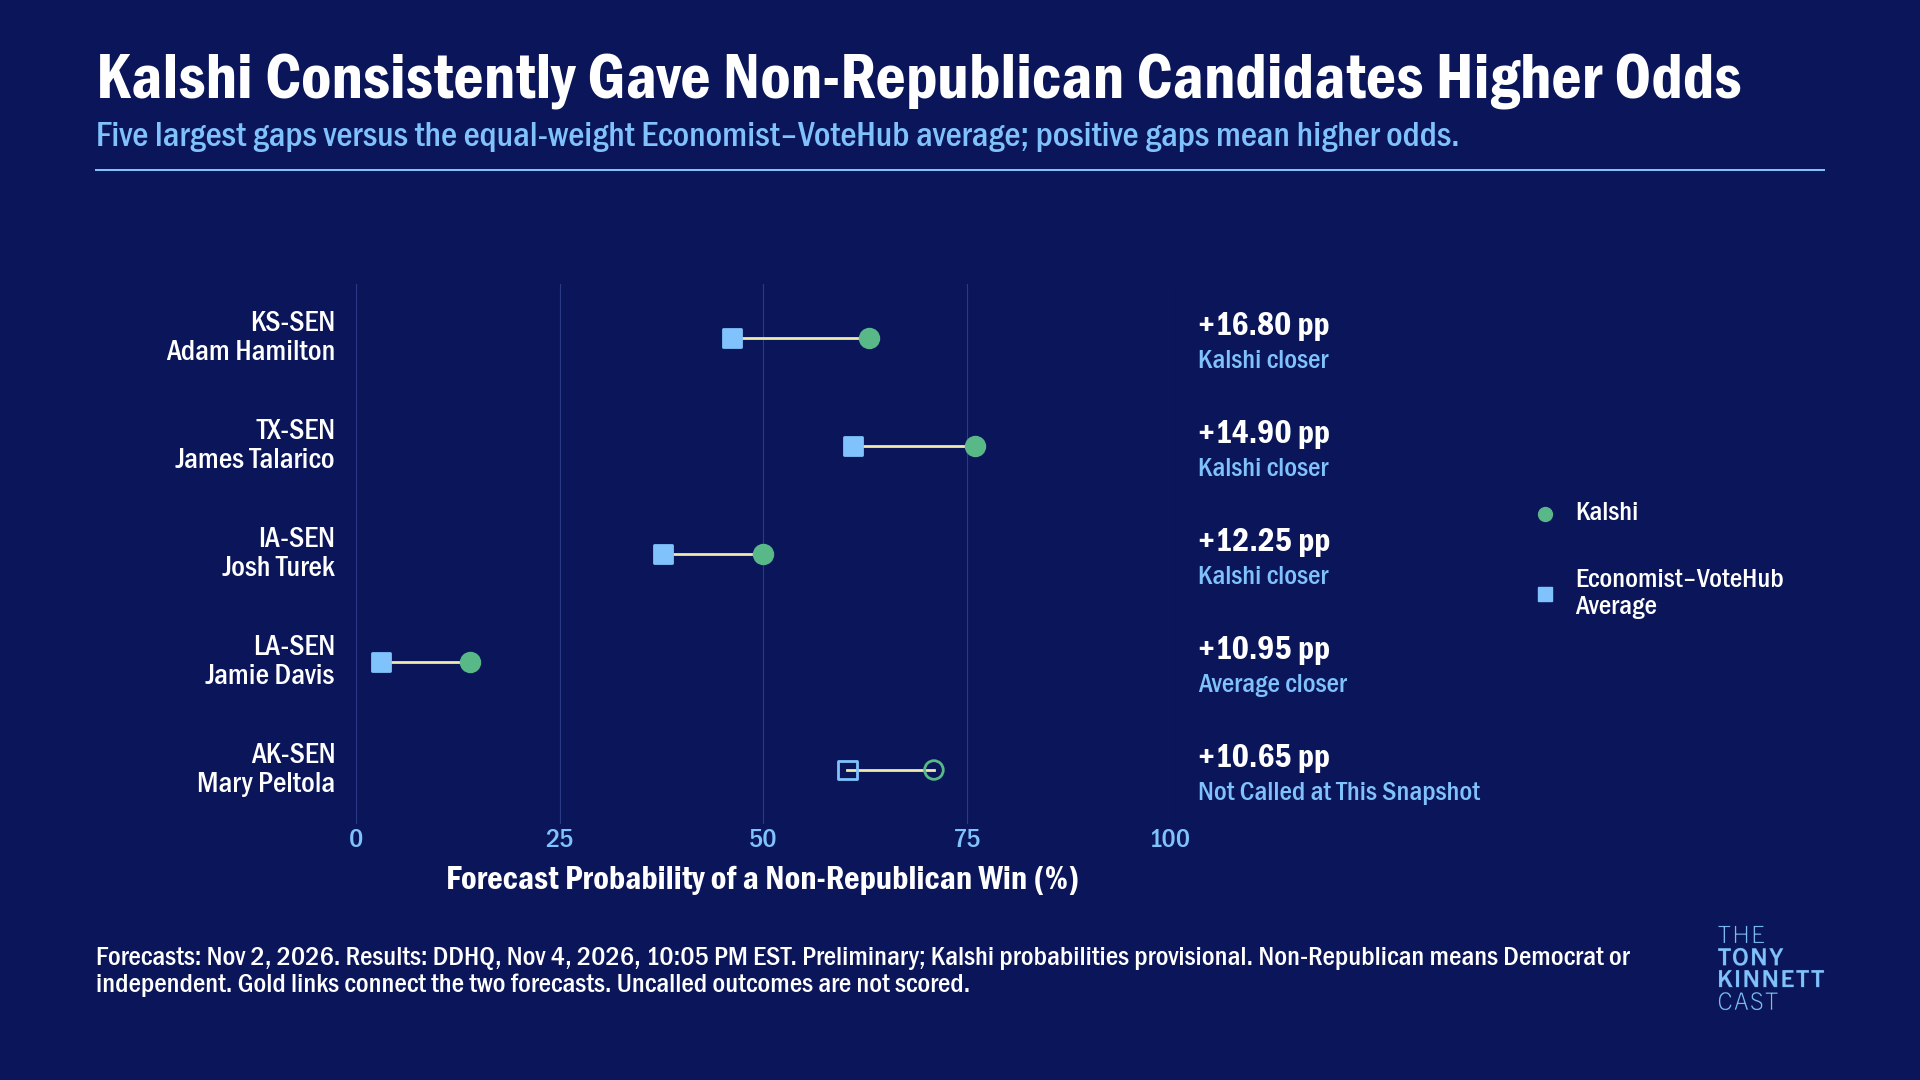

Against **Economist–VoteHub Average**, Kalshi gave the non-Republican candidate a higher probability in **6 of 7 Toss-Ups**, and a lower probability in 1. Toss-Up outcomes excluded from closeness scoring: 1. The direction count includes those forecasts.

The largest absolute gap was **KS-SEN: +16.80 percentage points**. Kalshi was closer to the called outcome.

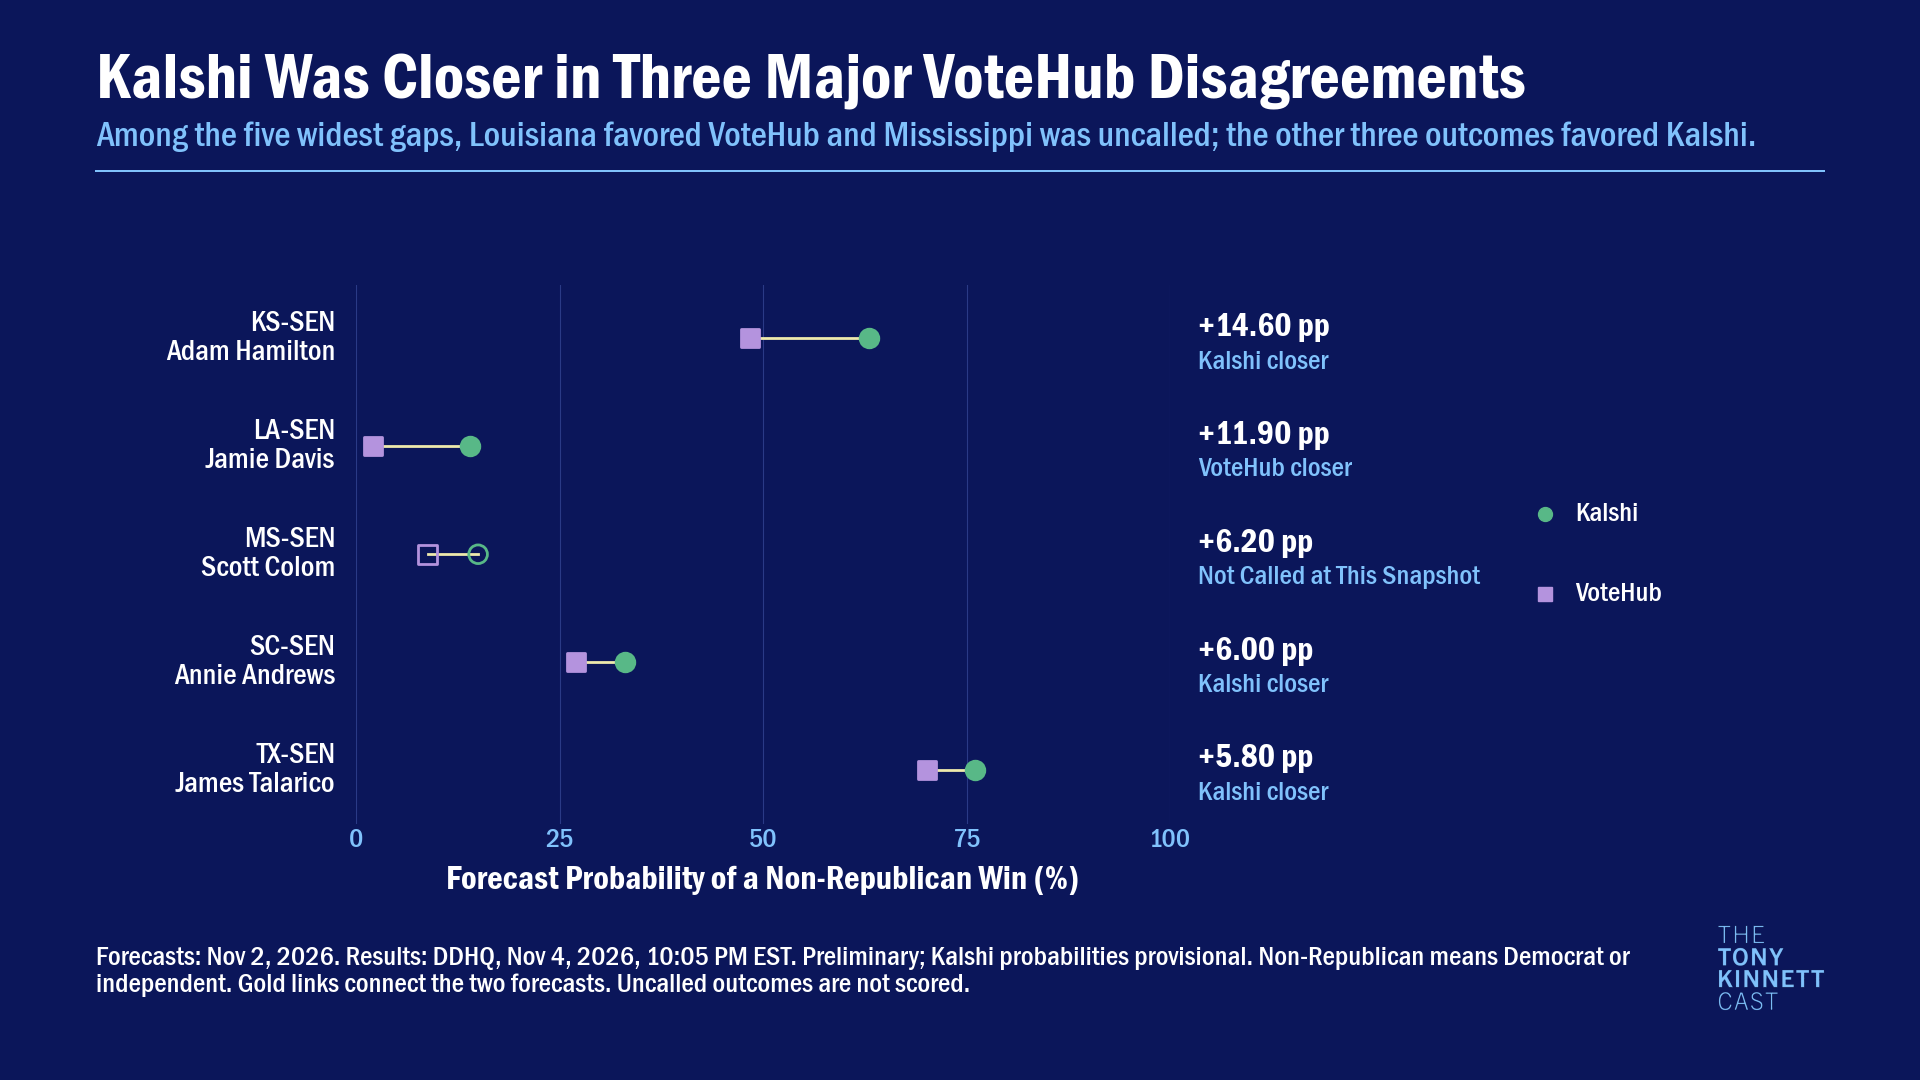

Against **VoteHub**, Kalshi gave the non-Republican candidate a higher probability in **6 of 7 Toss-Ups**, and a lower probability in 1. Toss-Up outcomes excluded from closeness scoring: 1. The direction count includes those forecasts.

The largest absolute gap was **KS-SEN: +14.60 percentage points**. Kalshi was closer to the called outcome.

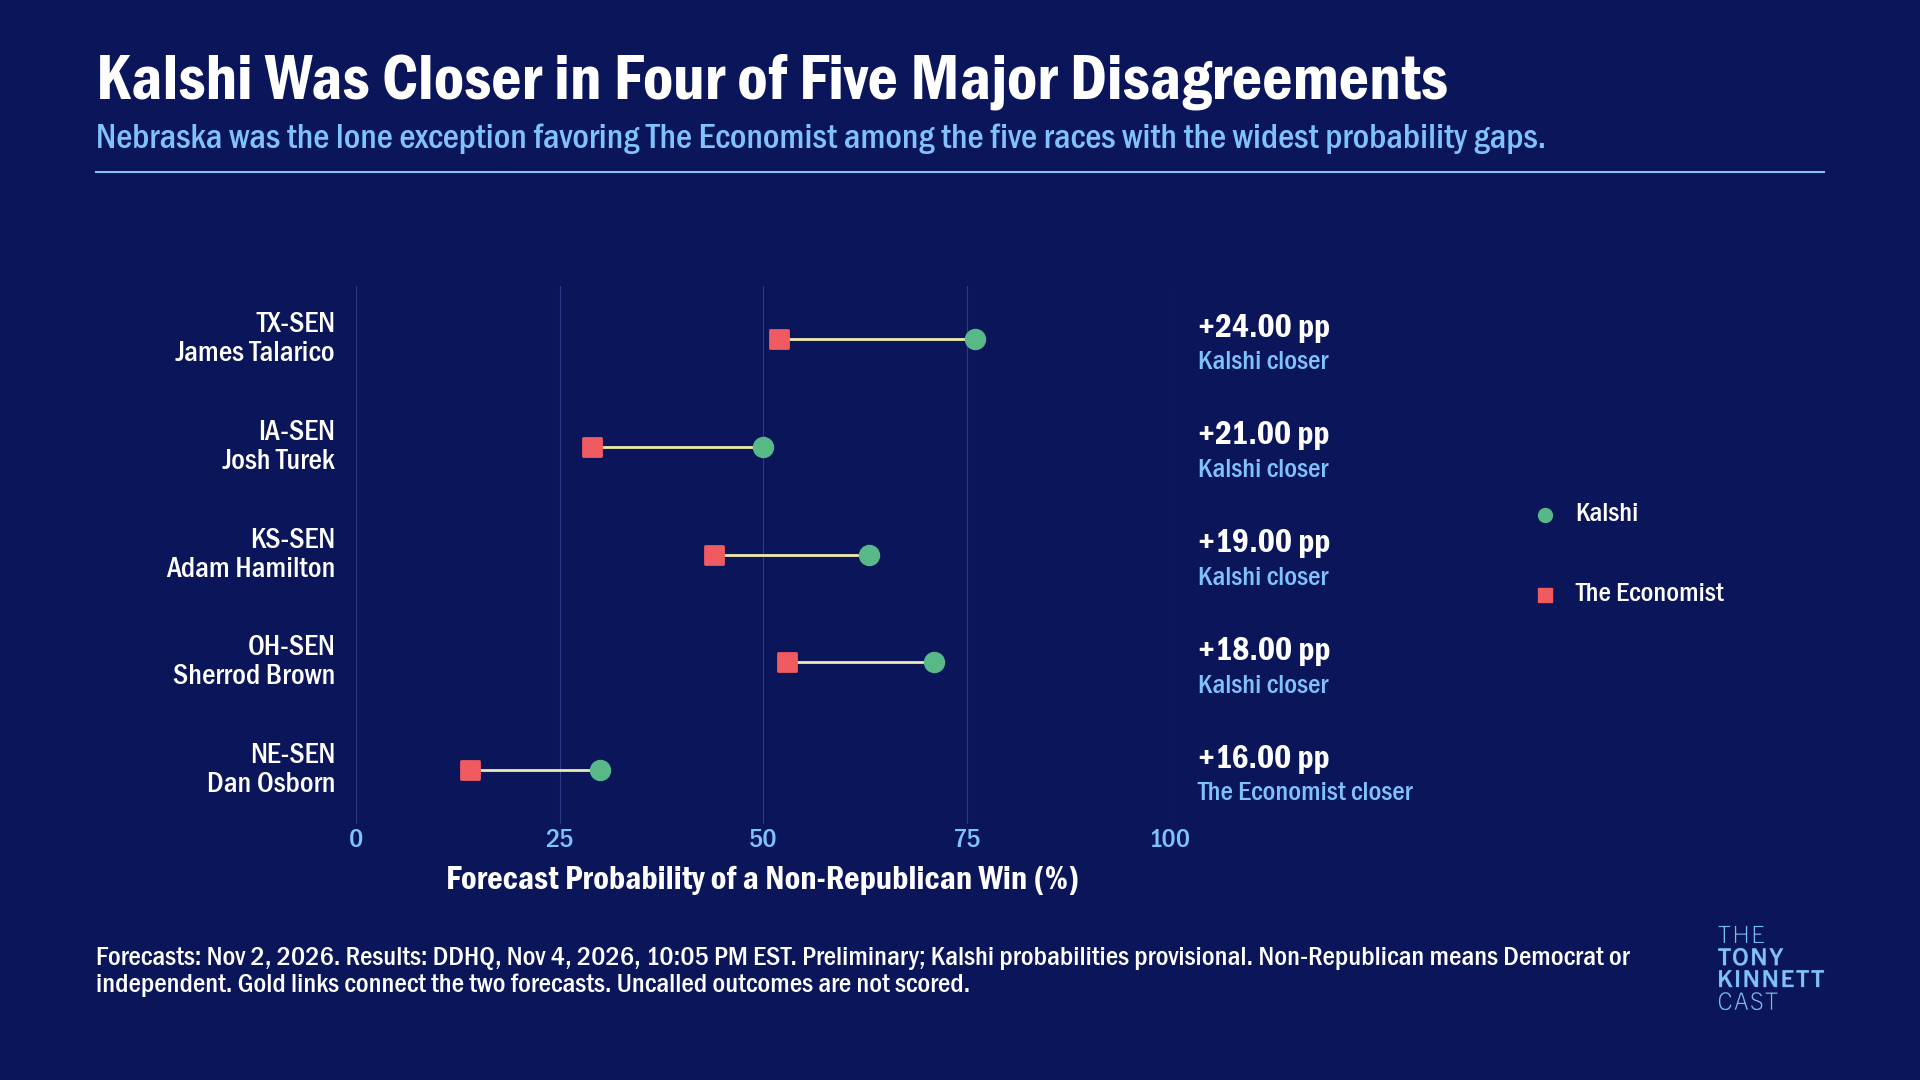

Against **The Economist**, Kalshi gave the non-Republican candidate a higher probability in **6 of 7 Toss-Ups**, and a lower probability in 1. Toss-Up outcomes excluded from closeness scoring: 1. The direction count includes those forecasts.

The largest absolute gap was **TX-SEN: +24.00 percentage points**. Kalshi was closer to the called outcome.

In [5]:
def disagreement_table(frame, reference, label):
    pair = record(f'disagreements/{label}', paired_difference(frame, 'p_kalshi', reference))
    result = pd.DataFrame({
        'candidate_a': frame.Candidate_A,
        'candidate_b': frame.Candidate_B,
        'cook_rating': frame.Cook_Rating,
        'kalshi_a_probability': frame.p_kalshi,
        'comparator_a_probability': frame[reference],
        'gap_pp': 100 * (frame.p_kalshi - frame[reference]),
        'eligible': frame.call_eligible,
        'winner': frame.result_winner,
    })
    result['paired_brier_difference'] = pair.per_race.difference.reindex(result.index)
    result['closer'] = 'Unavailable'
    evaluated = result.paired_brier_difference.notna()
    gap = result.paired_brier_difference
    result.loc[evaluated & gap.lt(-1e-12), 'closer'] = 'Kalshi'
    result.loc[evaluated & gap.gt(1e-12), 'closer'] = label
    result.loc[evaluated & gap.abs().le(1e-12), 'closer'] = 'Tie'
    result['absolute_gap_pp'] = result.gap_pp.abs()
    return result.reset_index().sort_values(
        ['absolute_gap_pp', 'race_id'],
        ascending=[False, True],
        kind='stable',
    ).reset_index(drop=True)
disagreements = {}
comparisons = [
    ('p_model_mean', 'Mixed benchmark', '04-gap-mixed'),
    ('p_votehub', 'VoteHub', '05-gap-votehub'),
    ('p_economist', 'Economist', '06-gap-economist'),
]
for reference, label, stem in comparisons:
    rows = disagreement_table(senate, reference, label)
    disagreements[label] = rows
    save_table(rows, stem + '_all')
    frame = rows.head(5).copy()
    comparator = {
        'Mixed benchmark': 'Economist–VoteHub Average',
        'VoteHub': 'VoteHub',
        'Economist': 'The Economist',
    }[label]
    evaluated = frame[frame.eligible]
    if label == 'Mixed benchmark':
        title = 'Kalshi Consistently Gave Non-Republican Candidates Higher Odds'
        subtitle = 'Five largest gaps versus the equal-weight Economist–VoteHub average; positive gaps mean higher odds.'
    elif label == 'VoteHub':
        current_pattern = len(evaluated) == 4 and evaluated.closer.eq('Kalshi').sum() == 3 and (evaluated.loc[
            evaluated.closer.eq('VoteHub'),
            'race_id',
        ].tolist() == ['LA-SEN']) and (frame.loc[~frame.eligible, 'race_id'].tolist() == ['MS-SEN']) and (senate.loc['MS-SEN', 'result_call_status'] in ('pending', 'unverified'))
        title = 'Kalshi Was Closer in Three Major VoteHub Disagreements' if current_pattern else 'The Largest Kalshi–VoteHub Disagreements'
        subtitle = 'Among the five widest gaps, Louisiana favored VoteHub and Mississippi was uncalled; the other three outcomes favored Kalshi.' if current_pattern else 'Five largest probability gaps against VoteHub; outcome closeness is assessed only for eligible races.'
    else:
        current_pattern = len(evaluated) == 5 and evaluated.closer.eq('Kalshi').sum() == 4 and (evaluated.loc[
            evaluated.closer.ne('Kalshi'),
            'race_id',
        ].tolist() == ['NE-SEN'])
        title = 'Kalshi Was Closer in Four of Five Major Disagreements' if current_pattern else 'The Largest Kalshi–Economist Disagreements'
        subtitle = 'Nebraska was the lone exception favoring The Economist among the five races with the widest probability gaps.' if current_pattern else 'Five largest probability gaps; closeness is assessed only for eligible outcomes.'
    cv = make_canvas(
        title,
        subtitle=subtitle,
        source=footer('Non-Republican means Democrat or independent. Gold links connect the two forecasts. Uncalled outcomes are not scored.'),
    )
    reference_color = {
        'Mixed benchmark': BLUE,
        'VoteHub': colors['votehub'],
        'Economist': colors['economist'],
    }[label]
    ax = cv.axes(left_pad=260, right_pad=654, bottom_pad=70, top_pad=90)
    # Separate columns hold per-race results and the centered source legend.
    legend_center = (ax.get_position().y0 + ax.get_position().y1) * cv.H / 2
    legend_labels = []
    for offset, name, color, marker in [(40, 'Kalshi', colors['kalshi'], 'o'), (-40, comparator, reference_color, 's')]:
        legend_y = legend_center + offset * cv.scale
        cv.fig.add_artist(Line2D(
            [1545 * cv.scale / cv.W],
            [legend_y / cv.H],
            transform=cv.fig.transFigure,
            marker=marker,
            markersize=10,
            linestyle='none',
            color=color,
        ))
        legend_labels.append(cv.fig.text(
            1575 * cv.scale / cv.W,
            legend_y / cv.H,
            name.replace(' Average', '\nAverage'),
            ha='left',
            va='center',
            color='white',
            fontproperties=cv.fp('body'),
            fontsize=28 * 0.72,
        ))
    for i, row in enumerate(frame.itertuples()):
        values = [100 * row.kalshi_a_probability, 100 * row.comparator_a_probability]
        link = ax.plot(values, [i, i], color=GOLD, linewidth=2, zorder=1)[0]
        assert link.get_color() == GOLD
        for value, color, marker in zip(values, [colors['kalshi'], reference_color], ['o', 's']):
            artist = ax.scatter(
                [value],
                [i],
                s=180,
                marker=marker,
                facecolors=color if row.eligible else 'none',
                edgecolors=color,
                linewidths=2,
                zorder=3,
            )
            np.testing.assert_allclose(artist.get_offsets()[0, 0], value)
        ax.annotate(
            f'{row.race_id}\n{row.candidate_a}',
            (0, i),
            xytext=(-15, 0),
            textcoords='offset points',
            ha='right',
            va='center',
            color='white',
            fontproperties=cv.fp('body'),
            fontsize=21.6,
        )
        ax.annotate(
            f'{row.gap_pp:+.2f} pp',
            (100, i),
            xytext=(20, 8),
            textcoords='offset points',
            ha='left',
            va='center',
            color='white',
            fontproperties=cv.fp('emphasis'),
            fontsize=24,
        )
        if not row.eligible:
            closer = 'Not Called at This Snapshot' if senate.loc[row.race_id, 'result_call_status'] in ('pending', 'unverified') else 'Outcome Not Eligible'
        else:
            closer = 'Equal loss' if row.closer == 'Tie' else ('The Economist' if row.closer == 'Economist' else 'Average' if row.closer == 'Mixed benchmark' else row.closer) + ' closer'
        ax.annotate(
            closer,
            (100, i),
            xytext=(20, -17),
            textcoords='offset points',
            ha='left',
            va='center',
            color=BLUE,
            fontproperties=cv.fp('body'),
            fontsize=20.2,
        )
    ax.set(
        xlim=(0, 100),
        ylim=(len(frame) - 0.5, -0.5),
        yticks=[],
        xticks=[0, 25, 50, 75, 100],
        xlabel='Forecast Probability of a Non-Republican Win (%)',
    )
    ax.xaxis.labelpad += 8 * cv.scale * 0.72
    ax.xaxis.grid(True, color='#2A3A86')
    ax.set_axisbelow(True)
    layout_checks[stem] = {'connector_colors': [line.get_color() for line in ax.lines], 'plot_left_px': ax.get_position().x0 * cv.W, 'plot_right_px': ax.get_position().x1 * cv.W, 'legend_right_rail': True, 'legend_center_px': legend_center, 'legend_label_bounds': [list(t.get_window_extent(cv.fig.canvas.get_renderer()).bounds) for t in legend_labels]}
    export_chart(cv, stem, frame)
    toss = rows[rows.cook_rating.eq('Toss-Up')]
    above = int(toss.gap_pp.gt(1e-10).sum())
    below = int(toss.gap_pp.lt(-1e-10).sum())
    say(f'Against **{comparator}**, Kalshi gave the non-Republican candidate a higher probability in **{above} of {len(toss)} Toss-Ups**, and a lower probability in {below}. Toss-Up outcomes excluded from closeness scoring: {int((~toss.eligible).sum())}. The direction count includes those forecasts.')
    top = frame.iloc[0]
    say(f'The largest absolute gap was **{top.race_id}: {top.gap_pp:+.2f} percentage points**. ' + (f"{('The Economist' if top.closer == 'Economist' else top.closer)} was closer to the called outcome." if top.eligible and top.closer != 'Tie' else 'The forecasts had equal loss.' if top.eligible else 'Its outcome is not eligible for scoring.'))

## 5. House Control and Seat Error
Control can be established before all 435 districts resolve. The approved threshold method requires verified DDHQ-called districts reaching 218 seats. Recorded counts without matching evidence do not qualify.

Cook rated 222 seats in Democrats' favor—enough for control if those seats held, without winning any Toss-Ups. Its directional call is separate from the numerical control probabilities. Final seat error requires complete counts and finality evidence.

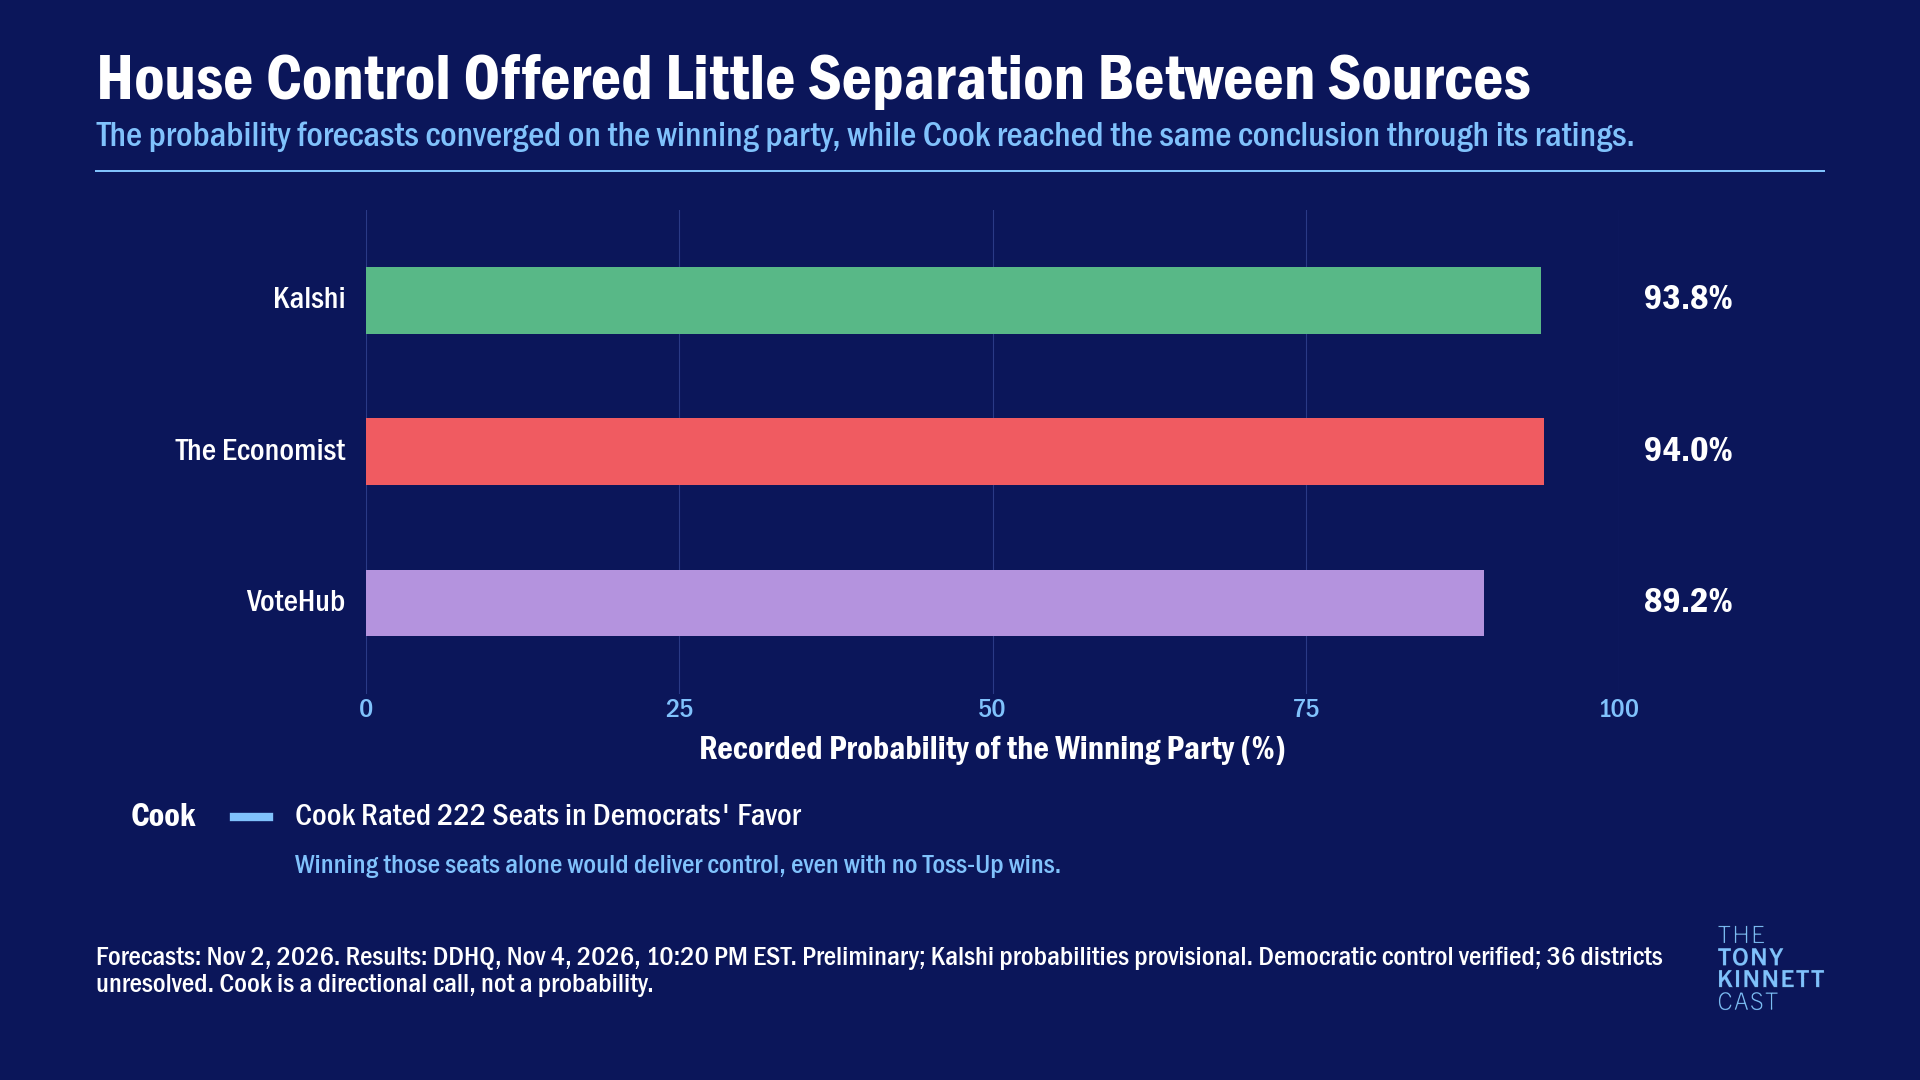

**Democratic control** is established by verified district calls reaching 218 seats. 36 districts remain unresolved. Cook's 222 Democratic-favored seats supported its directional call.

Source,Forecast seats,Signed error,Absolute error
Cook,229.38,—,—
The Economist,235,—,—
VoteHub,238.80,—,—


Method,Forecast Democratic seats
Directional hit rates (primary),229.38
Symmetric mapping,230.60
Toss-Ups split 50/50,229.77
Deterministic allocation,231


**Final seat errors are withheld** until all districts resolve and final counts are documented. Current called seats are not final actuals. National-vote comparisons have separate completeness and comparability requirements.

In [6]:
house = data.house.iloc[0]
control_eligible = bool(house.control_eligible)
control_rows = []
for source in ['Kalshi', 'Economist', 'VoteHub Complete']:
    result = record(f'house_control/{source}', house_control(data, SOURCES[source][0]))
    published = {'Kalshi': 'Kalshi', 'Economist': 'Economist', 'VoteHub Complete': 'VoteHub'}[source]
    value = float(house[f"{published}_{('DEM' if house.y == 1 else 'GOP')}_Probability"]) if control_eligible else None
    control_rows.append({
        'source': source,
        'winning_party': house.result_control if control_eligible else 'Unavailable',
        'winner_probability': value,
        'status': result.status,
    })
control_table = pd.DataFrame(control_rows)
save_table(control_table, 'house_control')
cook_control = record('house_control/Cook', house_control(data, 'cook'))
cook_firm = sum((house[f'Cook_{r}_Rating'] for r in ['SolidD', 'LikelyD', 'LeanD']))
save_table(
    pd.DataFrame([{
        'source': 'Cook',
        'forecast': 'Democratic control',
        'firm_dem_seats': cook_firm,
        'status': cook_control.status,
        'correct': cook_control.value['correct'] if cook_control.value else None,
        'calls_made': cook_control.value['calls_made'] if cook_control.value else None,
    }]),
    'house_cook_call',
)
save_table(
    pd.DataFrame([{
        'recorded_dem_seats': house.result_dem_seats,
        'recorded_gop_seats': house.result_gop_seats,
        'undecided': house.result_undecided_seats,
        'control_eligible': control_eligible,
        'seats_final': bool(house.seats_eligible),
        'control_method': house.result_control_method,
    }]),
    'house_status',
)
if control_eligible:
    control_table['winner_probability_pct'] = 100 * control_table.winner_probability
    all_favored_winner = control_table.winner_probability.gt(0.5).all() and bool(cook_control.value['correct'])
    cv = make_canvas(
        'House Control Offered Little Separation Between Sources',
        subtitle='The probability forecasts converged on the winning party, while Cook reached the same conclusion through its ratings.' if all_favored_winner else 'The probability forecasts favored the same party, while Cook reached the same conclusion through its ratings.',
        source=footer(
            f'{house.result_control} control verified; {int(house.result_undecided_seats)} districts unresolved. Cook is a directional call, not a probability.',
            'House',
        ),
    )
    ax = cv.axes(left_pad=270, right_pad=205, bottom_pad=200, top_pad=15)
    bars = ax.barh(np.arange(3), control_table.winner_probability_pct, height=0.44, color=[colors[SOURCES[s][1]] for s in control_table.source])
    np.testing.assert_allclose([b.get_width() for b in bars], control_table.winner_probability_pct)
    ax.set(
        xlim=(0, 100),
        ylim=(2.6, -0.6),
        yticks=[],
        xticks=[0, 25, 50, 75, 100],
        xlabel='Recorded Probability of the Winning Party (%)',
    )
    ax.xaxis.labelpad += 8 * cv.scale * 0.72
    ax.xaxis.grid(True, color='#2A3A86')
    ax.set_axisbelow(True)
    for i, row in enumerate(control_table.itertuples()):
        ax.annotate(
            display_names[row.source],
            (0, i),
            xytext=(-15, 0),
            textcoords='offset points',
            ha='right',
            va='center',
            color='white',
            fontproperties=cv.fp('body'),
            fontsize=23,
        )
        ax.annotate(
            f'{row.winner_probability_pct:.1f}%',
            (100, i),
            xytext=(18, 0),
            textcoords='offset points',
            ha='left',
            va='center',
            color='white',
            fontproperties=cv.fp('emphasis'),
            fontsize=26,
        )
    text(cv, 0.02, 0.11, 'Cook', px=34, role='emphasis')
    rule(cv, 0.11, 0.08, 0.1, color=colors['cook'], width=6)
    text(cv, 0.115, 0.11, f"Cook Rated {int(cook_firm)} Seats in Democrats' Favor", px=32)
    text(
        cv,
        0.115,
        0.04,
        'Winning those seats alone would deliver control, even with no Toss-Up wins.',
        px=28,
        color=BLUE,
    )
    export_chart(cv, '07-house-control', control_table)
    method = 'verified district calls reaching 218 seats' if house.result_control_method == 'district_threshold' else 'a verified chamber projection'
    say(f"**{house.result_control} control** is established by {method}. {int(house.result_undecided_seats)} districts remain unresolved. Cook's {int(cook_firm)} Democratic-favored seats supported its directional call.")
else:
    say('**House control scoring is unavailable for this snapshot:** matching verified DDHQ evidence is missing. The November 4 archive can be selected separately; its outcome is not substituted into this run.')
seat_rows = []
for source, key in [('Cook', 'cook'), ('Economist', 'economist'), ('VoteHub Complete', 'votehub')]:
    result = record(f'house_seats/{source}', house_seat_error(data, key))
    expected = house_expected_seats(house) if key == 'cook' else float(house[f"{('Economist' if key == 'economist' else 'VoteHub')}_DEM_Seats"])
    value = result.value or {}
    seat_rows.append({
        'source': source,
        'forecast_dem_seats': expected,
        'status': result.status,
        'actual_final_dem_seats': value.get('actual'),
        'signed_error': value.get('signed_error'),
        'absolute_error': value.get('absolute_error'),
    })
seats = pd.DataFrame(seat_rows)
save_table(seats, 'house_seats')
view = seats[['source', 'forecast_dem_seats', 'signed_error', 'absolute_error']].copy()
view.source = view.source.map(display_names)
present(
    'Democratic House seats · forecasts and final-only errors',
    view.rename(columns={
        'source': 'Source',
        'forecast_dem_seats': 'Forecast seats',
        'signed_error': 'Signed error',
        'absolute_error': 'Absolute error',
    }),
)
methods = pd.DataFrame([{'cook_method': m, 'forecast_dem_seats': house_expected_seats(house, m)} for m in ['directional', 'symmetric', 'tossup_half', 'deterministic']])
save_table(methods, 'cook_house_methods')
method_view = methods.replace({'cook_method': {
    'directional': 'Directional hit rates (primary)',
    'symmetric': 'Symmetric mapping',
    'tossup_half': 'Toss-Ups split 50/50',
    'deterministic': 'Deterministic allocation',
}})
present(
    'Cook seat calculations · directional is primary',
    method_view.rename(columns={
        'cook_method': 'Method',
        'forecast_dem_seats': 'Forecast Democratic seats',
    }),
)
if not house.seats_eligible:
    say('**Final seat errors are withheld** until all districts resolve and final counts are documented. Current called seats are not final actuals. National-vote comparisons have separate completeness and comparability requirements.')
else:
    say('Final seat errors are available for this selected snapshot. Signed error is forecast minus actual. Synthetic counts remain software fixtures.')

## 6. Outcomes by Cook Rating
Each dot represents one race, ordered from Likely Democratic through Toss-Up to Likely Republican. Blue dots show Non-GOP wins, red dots show GOP wins, and hollow dots show outcomes excluded from scoring. Non-GOP includes Democrats and independents.

A gold ring identifies South Carolina when its result defeats Cook's directional favorite. These small groups describe this election, not long-run calibration.

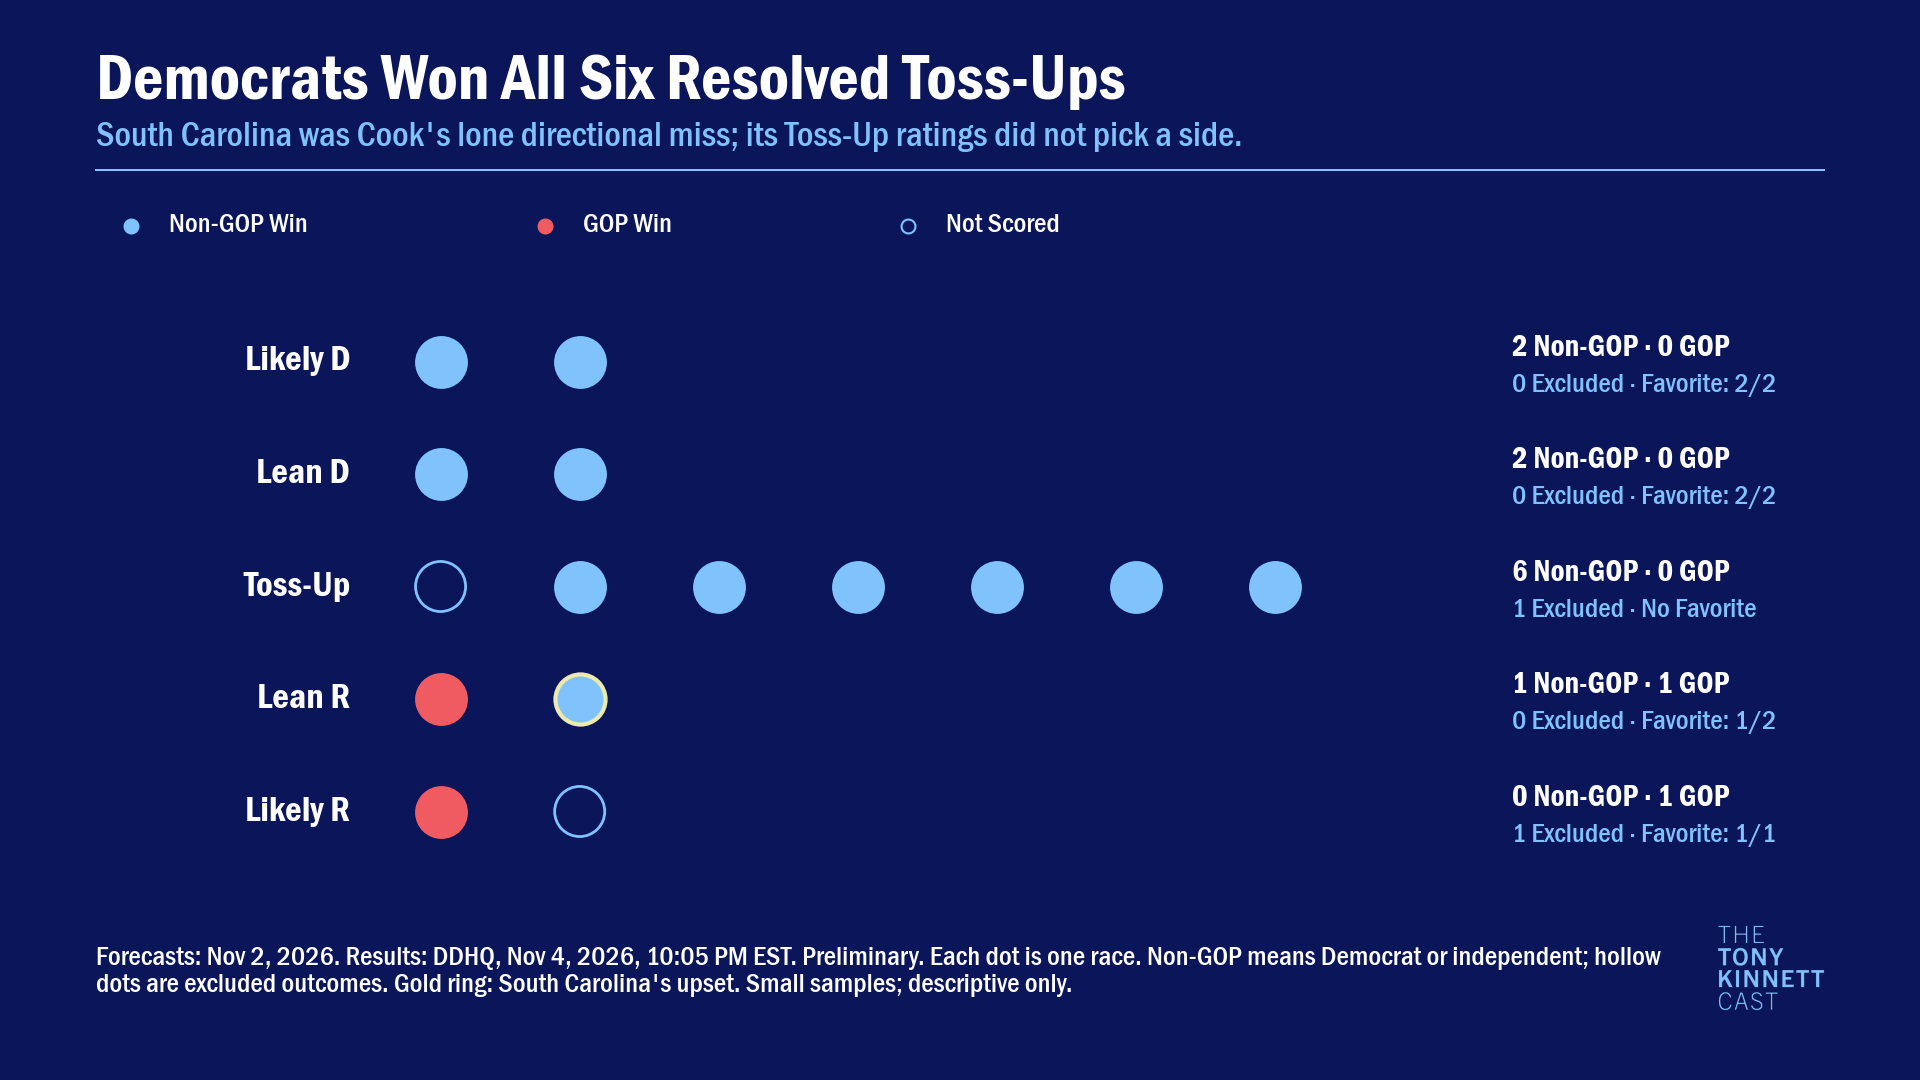

The Solid buckets add 20 planned races, with 20 eligible outcomes and 20 correct directional calls. They are retained in the full supporting table.

Of 7 planned Toss-Ups, **6 are eligible**: non-Republican candidates won 6 and Republican candidates won 0. Excluded outcomes: 1. Cook made no directional call in this bucket.

Cook's directional favorite lost in **SC-SEN (Annie Andrews)**. These few outcomes cannot establish the calibration of a rating category.

In [7]:
bucket_rows = []
for rating in ['Solid D', 'Solid R', 'Likely D', 'Likely R', 'Lean D', 'Lean R', 'Toss-Up']:
    frame = senate[senate.Cook_Rating.eq(rating)]
    result = record(f'bucket/{rating}', calls_correct(frame, 'p_cook_primary'))
    rows = result.per_race
    bucket_rows.append({
        'rating': rating,
        'planned': len(frame),
        'eligible': len(rows),
        'excluded': len(frame) - len(rows),
        'candidate_a_wins': int(rows.y.eq(1).sum()),
        'candidate_b_wins': int(rows.y.eq(0).sum()),
        'favored_side_hits': result.value['correct'] if result.value and rating != 'Toss-Up' else None,
        'directional_calls': result.value['calls_made'] if result.value and rating != 'Toss-Up' else None,
    })
buckets = pd.DataFrame(bucket_rows)
rating_order = ['Likely D', 'Lean D', 'Toss-Up', 'Lean R', 'Likely R']
competitive = buckets.set_index('rating').loc[rating_order].reset_index()
save_table(buckets, 'cook_all_buckets')
save_table(competitive, 'cook_competitive_buckets')
assert buckets.planned.sum() == len(senate)
assert buckets.eligible.sum() == senate.call_eligible.sum()
assert (buckets.candidate_a_wins + buckets.candidate_b_wins).equals(buckets.eligible)
toss = competitive[competitive.rating.eq('Toss-Up')].iloc[0]
resolved_toss = senate[senate.Cook_Rating.eq('Toss-Up') & senate.call_eligible]
all_democratic_toss = len(resolved_toss) > 0 and resolved_toss.y.eq(1).all() and resolved_toss.Candidate_A_Party.eq('Democratic').all()
number_words = {1: 'One', 2: 'Two', 3: 'Three', 4: 'Four', 5: 'Five', 6: 'Six', 7: 'Seven'}
headline = f'Democrats Won All {number_words.get(
    len(resolved_toss),
    str(len(resolved_toss)),
)} Resolved Toss-Ups' if all_democratic_toss else 'Resolved Outcomes by Cook Rating'
upsets = senate[senate.call_eligible & senate.p_cook_primary.ne(0.5) & senate.p_cook_primary.gt(0.5).ne(senate.y.eq(1))]
subtitle = "South Carolina was Cook's lone directional miss; its Toss-Up ratings did not pick a side." if upsets.index.tolist() == ['SC-SEN'] else 'Non-GOP and GOP outcomes are shown separately; Toss-Ups have no favored side.'
race_rows = []
for rating in rating_order:
    for dot_index, (race_id, row) in enumerate(senate[senate.Cook_Rating.eq(rating)].sort_index().iterrows()):
        eligible = bool(row.call_eligible)
        directional = row.p_cook_primary != 0.5
        favorite_correct = bool((row.p_cook_primary > 0.5) == bool(row.y)) if eligible and directional else None
        outcome = 'Non-GOP' if eligible and row.y == 1 else 'GOP' if eligible else 'Excluded'
        race_rows.append({
            'race_id': race_id,
            'rating': rating,
            'dot_index': dot_index,
            'outcome': outcome,
            'eligible': eligible,
            'winner': row.result_winner if eligible else None,
            'favorite_correct': favorite_correct,
            'highlight_sc': race_id == 'SC-SEN' and favorite_correct is False,
        })
dot_data = pd.DataFrame(race_rows)
ring_note = " Gold ring: South Carolina's upset." if dot_data.highlight_sc.any() else ''
cv = make_canvas(
    headline,
    subtitle=subtitle,
    source=footer(
        'Each dot is one race. Non-GOP means Democrat or independent; hollow dots are excluded outcomes.' + ring_note + ' Small samples; descriptive only.',
        kalshi=False,
    ),
)
party = party_colors()
for x, label, color, hollow in [(0.02, 'Non-GOP Win', BLUE, False), (0.26, 'GOP Win', party['republican'], False), (0.47, 'Not Scored', BLUE, True)]:
    x0, y0, x1, y1 = cv.plot_rect
    cv.fig.add_artist(Line2D(
        [(x0 + x * (x1 - x0)) / cv.W],
        [(y0 + 0.955 * (y1 - y0)) / cv.H],
        transform=cv.fig.transFigure,
        marker='o',
        markersize=10,
        linestyle='none',
        markerfacecolor='none' if hollow else color,
        markeredgecolor=color,
        markeredgewidth=1.5,
    ))
    text(cv, x + 0.022, 0.955, label, px=28)
ax = cv.axes(left_pad=275, right_pad=340, bottom_pad=15, top_pad=100)
ax.set(xlim=(0, 8), ylim=(4.6, -0.6), xticks=[], yticks=[])
for i, rating in enumerate(rating_order):
    group = dot_data[dot_data.rating.eq(rating)]
    summary = competitive[competitive.rating.eq(rating)].iloc[0]
    ax.annotate(
        rating,
        (0, i),
        xytext=(-15, 0),
        textcoords='offset points',
        ha='right',
        va='center',
        color='white',
        fontproperties=cv.fp('emphasis'),
        fontsize=26,
    )
    for row in group.itertuples():
        color = BLUE if row.outcome != 'GOP' else party['republican']
        artist = ax.scatter(
            [row.dot_index + 0.5],
            [i],
            s=1300,
            facecolors='none' if row.outcome == 'Excluded' else color,
            edgecolors=GOLD if row.highlight_sc else color,
            linewidths=3 if row.highlight_sc else 2,
            zorder=3,
        )
        np.testing.assert_allclose(artist.get_offsets()[0], [row.dot_index + 0.5, i])
    ax.annotate(
        f'{int(summary.candidate_a_wins)} Non-GOP · {int(summary.candidate_b_wins)} GOP',
        (8, i),
        xytext=(20, 10),
        textcoords='offset points',
        ha='left',
        va='center',
        color='white',
        fontproperties=cv.fp('emphasis'),
        fontsize=22,
    )
    favorite = 'No Favorite' if rating == 'Toss-Up' else f'Favorite: {int(summary.favored_side_hits)}/{int(summary.directional_calls)}' if pd.notna(summary.favored_side_hits) else 'No Eligible Calls'
    ax.annotate(
        f'{int(summary.excluded)} Excluded · {favorite}',
        (8, i),
        xytext=(20, -17),
        textcoords='offset points',
        ha='left',
        va='center',
        color=BLUE,
        fontproperties=cv.fp('body'),
        fontsize=20.2,
    )
layout_checks['08-cook-rating-outcomes'] = {
    'rating_order': rating_order,
    'dots': len(dot_data),
    'sc_gold_ring': bool(dot_data.highlight_sc.any()),
}
export_chart(cv, '08-cook-rating-outcomes', dot_data)
solid = buckets[buckets.rating.str.startswith('Solid')]
say(f'The Solid buckets add {int(solid.planned.sum())} planned races, with {int(solid.eligible.sum())} eligible outcomes and {int(solid.favored_side_hits.sum())} correct directional calls. They are retained in the full supporting table.')
toss = competitive[competitive.rating.eq('Toss-Up')].iloc[0]
say(f'Of {int(toss.planned)} planned Toss-Ups, **{int(toss.eligible)} are eligible**: non-Republican candidates won {int(toss.candidate_a_wins)} and Republican candidates won {int(toss.candidate_b_wins)}. Excluded outcomes: {int(toss.excluded)}. Cook made no directional call in this bucket.')
upsets = senate[senate.call_eligible & senate.p_cook_primary.ne(0.5) & senate.p_cook_primary.gt(0.5).ne(senate.y.eq(1))]
if len(upsets):
    say("Cook's directional favorite lost in " + ', '.join((f'**{rid} ({row.result_winner})**' for rid, row in upsets.iterrows())) + '. These few outcomes cannot establish the calibration of a rating category.')

## Sensitivities and limitations
The six comparisons above are descriptive. The appendix checks the approved A/B-normalization sensitivity and alternative Cook mappings. Raw recorded Kalshi A probabilities remain primary. Normalization conditions on A or B winning; it does not replace frozen inputs.

In [8]:
sensitivity_rows = []
for label, column in [('Kalshi raw', 'p_kalshi'), ('Kalshi A/B normalized', 'p_kalshi_normalized'), ('Cook primary', 'p_cook_primary'), ('Cook Senate-only', 'p_cook_senate'), ('Cook wide', 'p_cook_wide')]:
    calls = record(f'sensitivity/calls/{label}', calls_correct(senate, column))
    counts = record(f'sensitivity/expected/{label}', expected_wins(senate, column))
    score = record(
        f'sensitivity/brier/{label}',
        probability_score(select_sample(senate, 'non_solid'), column),
    )
    value = calls.value or {}
    sensitivity_rows.append({
        'version': label,
        'correct': value.get('correct'),
        'calls_made': value.get('calls_made'),
        'full_field_expected': counts.value['full_field_expected'],
        'matched_expected': counts.value['eligible_expected'],
        'matched_actual': counts.value['eligible_actual'],
        'matched_signed_error': counts.value['signed_error'],
        'non_solid_brier': score.value,
        'non_solid_eligible': score.n_eligible,
    })
sensitivities = pd.DataFrame(sensitivity_rows)
save_table(sensitivities, 'sensitivities')
view = sensitivities[[
    'version',
    'correct',
    'calls_made',
    'full_field_expected',
    'matched_expected',
    'matched_signed_error',
]].copy()
present(
    'Sensitivity summary · forecast counts and matched errors',
    view.rename(columns={
        'version': 'Version',
        'correct': 'Correct',
        'calls_made': 'Calls made',
        'full_field_expected': 'Full-field forecast',
        'matched_expected': 'Matched forecast',
        'matched_signed_error': 'Matched error',
    }),
)
raw, normalized = (sensitivities.iloc[0], sensitivities.iloc[1])
counts_available = pd.notna(raw.correct) and pd.notna(normalized.correct)
unchanged_calls = raw.correct == normalized.correct and raw.calls_made == normalized.calls_made
say(f"A/B normalization {(('leaves call totals unchanged' if unchanged_calls else 'changes call totals') if counts_available else 'has no eligible call totals to compare')}. It changes full-field expected non-Republican wins by {normalized.full_field_expected - raw.full_field_expected:+.4f}. The table reports eligible-sample changes separately; counts and Brier scoring use no clipping.")
normalized_frame = senate.copy()
normalized_frame['p_kalshi'] = senate.p_kalshi_normalized
rank_changes = []
for reference, label in [('p_model_mean', 'Mixed benchmark'), ('p_votehub', 'VoteHub'), ('p_economist', 'Economist')]:
    alt = disagreement_table(normalized_frame, reference, label + ' normalized sensitivity')
    raw_rows = disagreements[label]
    aligned = raw_rows.set_index('race_id').join(
        alt.set_index('race_id')[['closer', 'gap_pp']],
        rsuffix='_normalized',
    )
    evaluated = aligned.eligible & aligned.paired_brier_difference.notna()
    raw_closer = aligned.closer.replace({label: 'Comparator'})
    alt_closer = aligned.closer_normalized.replace({label + ' normalized sensitivity': 'Comparator'})
    rank_changes.append({
        'comparison': label,
        'top_five_race_order_unchanged': raw_rows.race_id.head(5).tolist() == alt.race_id.head(5).tolist(),
        'changed_closer_classifications': int((raw_closer[evaluated] != alt_closer[evaluated]).sum()),
        'largest_absolute_gap_change_pp': float((aligned.gap_pp_normalized - aligned.gap_pp).abs().max()),
    })
save_table(pd.DataFrame(rank_changes), 'normalization_disagreements')
view = pd.DataFrame(rank_changes).rename(columns={
    'comparison': 'Comparison',
    'top_five_race_order_unchanged': 'Highlighted order',
    'changed_closer_classifications': 'Closeness changes',
    'largest_absolute_gap_change_pp': 'Maximum gap change (pp)',
})
view['Highlighted order'] = view['Highlighted order'].map({True: 'Unchanged', False: 'Changed'})
present('Kalshi normalization · disagreement sensitivity', view)
for change in rank_changes:
    say(f"Normalization {('preserves' if change['top_five_race_order_unchanged'] else 'changes')} the five highlighted races/order against {change['comparison']}; {change['changed_closer_classifications']} eligible outcome-closeness classifications change.")
normalized_winners = winner_probs.copy()
normalized_winners['Kalshi'] = senate.p_kalshi_normalized.reindex(winner_probs.index).where(
    senate.y.reindex(winner_probs.index).eq(1),
    1 - senate.p_kalshi_normalized.reindex(winner_probs.index),
)
ranking_same = lowest_with_ties(winner_probs, 'Kalshi').race_id.tolist() == lowest_with_ties(normalized_winners, 'Kalshi').race_id.tolist()
say(f"The bottom-five Kalshi winner ranking, including cutoff ties, {(('is unchanged' if ranking_same else 'changes') if len(winner_probs) else 'is unavailable because no winners are eligible')} under normalization. The sensitivity table reports changes to the highlighted disagreement rankings and outcome-closeness classifications.")
if control_eligible:
    normalized_winner = float(house.p_kalshi_normalized if house.y == 1 else 1 - house.p_kalshi_normalized)
    raw_winner = float(control_table.loc[
        control_table.source.eq('Kalshi'),
        'winner_probability',
    ].iloc[0])
    save_table(
        pd.DataFrame([{
            'raw_winner_probability': raw_winner,
            'normalized_winner_probability': normalized_winner,
            'difference_pp': 100 * (normalized_winner - raw_winner),
        }]),
        'house_normalization',
    )
save_table(pd.DataFrame([{'source': key, 'eligible': value} for key, value in data.diagnostics['share_eligible'].items()]), 'vote_share_eligibility')
say('**Remaining limits.** Only verified calls enter outcome comparisons; a vote lead does not establish a winner. Known active recounts are excluded, and unknown recount status remains unknown. Vote-share scoring needs documented completeness and matching forecast targets, including ranked-choice rounds where applicable. Final House seats and Senate caucus totals retain their separate evidence gates.')
say('**Source limits.** The original Kalshi price measure and KY-SEN contract identity remain unresolved; probability scoring is provisional. Source publication/retrieval metadata are incomplete. VoteHub includes Kalshi and Cook inputs, and no market-free VoteHub Legacy snapshot was collected. A single election with correlated close races cannot establish general superiority.')

def json_default(value):
    if isinstance(value, np.generic):
        return value.item()
    raise TypeError(type(value).__name__)
artifact_hashes = {}
for item in figure_records:
    for key, directory in [('image', ctx.figures_dir), ('data', ctx.tables_dir)]:
        artifact_hashes[item[key]] = sha256(directory / item[key])
provenance = {
    **metadata,
    'input_hashes': data.hashes,
    'qualifications': data.diagnostics['qualifications'],
    'graphics_assets': graphics_assets(),
    'editable_source': 'notebooks/01_congress_scorecard.ipynb',
    'figures': figure_records,
    'artifact_hashes': artifact_hashes,
    'score_results': score_records,
}
_ = (ctx.tables_dir / 'analysis-provenance.json').write_text(
    json.dumps(provenance, indent=2, default=json_default),
    encoding='utf-8',
)

Version,Correct,Calls made,Full-field forecast,Matched forecast,Matched error
Kalshi raw,31,32,18.96,18.10,-1.90
Kalshi A/B normalized,31,32,18.95,18.10,-1.90
Cook primary,26,27,16.52,15.99,-4.01
Cook Senate-only,26,27,16.52,16.00,-4.00
Cook wide,26,27,16.52,15.92,-4.08


A/B normalization leaves call totals unchanged. It changes full-field expected non-Republican wins by -0.0072. The table reports eligible-sample changes separately; counts and Brier scoring use no clipping.

Comparison,Highlighted order,Closeness changes,Maximum gap change (pp)
Mixed benchmark,Changed,0,0.70
VoteHub,Unchanged,0,0.70
Economist,Unchanged,0,0.70


Normalization changes the five highlighted races/order against Mixed benchmark; 0 eligible outcome-closeness classifications change.

Normalization preserves the five highlighted races/order against VoteHub; 0 eligible outcome-closeness classifications change.

Normalization preserves the five highlighted races/order against Economist; 0 eligible outcome-closeness classifications change.

The bottom-five Kalshi winner ranking, including cutoff ties, is unchanged under normalization. The sensitivity table reports changes to the highlighted disagreement rankings and outcome-closeness classifications.

**Remaining limits.** Only verified calls enter outcome comparisons; a vote lead does not establish a winner. Known active recounts are excluded, and unknown recount status remains unknown. Vote-share scoring needs documented completeness and matching forecast targets, including ranked-choice rounds where applicable. Final House seats and Senate caucus totals retain their separate evidence gates.

**Source limits.** The original Kalshi price measure and KY-SEN contract identity remain unresolved; probability scoring is provisional. Source publication/retrieval metadata are incomplete. VoteHub includes Kalshi and Cook inputs, and no market-free VoteHub Legacy snapshot was collected. A single election with correlated close races cannot establish general superiority.